# Phase 3 RR: Hierarchical, context-aware Rhetorical Roles on the Phase-1 GQLA model

**Why the previous notebook got Macro-F1 ≈ 0.27, and what this one changes**

| Problem in the old notebook | Fix here |
|---|---|
| Each sentence was classified **in isolation** (last-token state only). Rhetorical roles are a *sequence* problem: a sentence's role depends on where it is in the judgment and on its neighbours. | **Hierarchical model**: GQLA encodes each sentence → a **BiLSTM over the whole document** (+ relative-position features + domain embedding) → label per sentence. |
| Heavy over-fitting: train loss 0.15 vs dev loss ≈ 6 (only 80 training documents). | Parameter-efficient adaptation (LoRA / LoRMA / adapters / BitFit), feature dropout, class-balanced loss, early stopping on dev. |
| Rare classes (Issue, Dissent, PrecedentOverruled, None) ignored by plain cross-entropy. | Square-root inverse-frequency class weights, prior correction at decode time. |
| Macro-F1 computed over all 13 labels even when a label does not occur in the dev set (counts as 0, capping the score). | Report **both**: sklearn default (labels present in gold ∪ predicted) and the strict 13-label version. |
| One model, one run. | 6 different experiments + cheap baselines + **ensemble** + Viterbi/transition smoothing. |

**Experiments (all start from your Phase-1 GQLA checkpoint)**

| ID | Technique | Notes |
|---|---|---|
| E1 | Full fine-tuning | reference |
| E2 | LoRA | additive low-rank update |
| E3 | **LoRMA** | multiplicative low-rank update `W' = (I + BA)·W` |
| E4 | Houlsby bottleneck adapters | after attention and FFN sub-layers |
| E5 | BitFit | bias-only tuning |
| E6 | **Knowledge distillation** | 5-layer student initialised from alternate Phase-1 layers, teacher = ensemble of E1–E5 |
| E0 / TF-IDF | Frozen-feature heads, TF-IDF + LR | cheap baselines and ensemble members, also give the “does context help?” ablation |

Run the cells top to bottom. Every experiment saves its probabilities to Drive, so after a Colab disconnect it is **skipped and reloaded** when you re-run.

## 1. Setup and configuration

In [ ]:
import os, re, json, math, random, unicodedata, gc, time, copy, pickle, itertools, zipfile
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score, classification_report, confusion_matrix

try:
    from google.colab import drive
    drive.mount('/content/drive'); IN_COLAB = True
except Exception:
    IN_COLAB = False

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)

# ---------------- paths: edit these ----------------
PHASE1_CACHE_DIR = "/content/drive/MyDrive/CS781/Capstone-Project/legal_dataset_cache"
CHECKPOINT_PATH  = os.path.join(PHASE1_CACHE_DIR, "gqla_checkpoints", "gqla_baseline_large.pt")
TOKENIZER_PATH   = os.path.join(PHASE1_CACHE_DIR, "final_bpe_en.json")
OUTPUT_DIR       = "/content/drive/MyDrive/CS781/Capstone-Project/Phase-3-v2"
DATA_DIR         = "./phase3_rr_data"
PROB_DIR         = os.path.join(OUTPUT_DIR, "probs")
for d in (OUTPUT_DIR, DATA_DIR, PROB_DIR): os.makedirs(d, exist_ok=True)

# ---------------- HF token: DO NOT hard-code it ----------------
# Colab: add a secret named HF_TOKEN (key icon in the left sidebar), or export HF_TOKEN in the environment.
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass
HF_TOKEN = HF_TOKEN or os.environ.get("HF_TOKEN")

# ---------------- model / training hyper-parameters ----------------
MAX_TOK        = 128     # max BPE tokens kept per sentence
WINDOW         = 32      # consecutive sentences per training window (BiLSTM sees windows in training, whole docs at test time)
WINDOWS_PER_BATCH = 2
ENC_MICRO_TRAIN = 32     # sentences pushed through GQLA at once while training
ENC_MICRO_EVAL  = 96
GRAD_CKPT      = True    # gradient checkpointing in GQLA layers (saves a lot of memory, ~30% slower)
HEAD_LR        = 2e-3
HEAD_WD        = 0.01
LABEL_SMOOTH   = 0.02
GRAD_CLIP      = 1.0
PATIENCE       = 5
N_POS_BINS     = 20
N_POS_F        = 6
FORCE_RERUN    = False   # True = ignore saved probabilities and retrain everything

EXPERIMENTS = {
    "E1_full":    dict(method="full",    lr=3e-5, epochs=10),
    "E2_lora":    dict(method="lora",    lr=3e-4, epochs=12, r=16, alpha=32),
    "E3_lorma":   dict(method="lorma",   lr=3e-4, epochs=12, r=16, alpha=16),
    "E4_adapter": dict(method="adapter", lr=5e-4, epochs=12, bottleneck=64),
    "E5_bitfit":  dict(method="bitfit",  lr=2e-3, epochs=12),
    "E6_kd":      dict(method="full",    lr=8e-5, epochs=14, student_layers=[1,3,5,7,9], kd_T=2.0, kd_alpha=0.7),
}

Mounted at /content/drive
Device: cuda


## 2. Load and clean the official Phase-3 data
Unlike the old cleaning step, **no sentence is ever dropped** (empty ones become `.`), so the number of predictions always equals the number of test sentences.

In [ ]:
from huggingface_hub import hf_hub_download
REPO_ID = "Exploration-Lab/CS-781-Capstone"
PHASE3_FILES = {
    "CL_train":"Phase_3_RR/Train/CL_train.json", "CL_dev":"Phase_3_RR/Train/CL_dev.json",
    "IT_train":"Phase_3_RR/Train/IT_train.json", "IT_dev":"Phase_3_RR/Train/IT_dev.json",
    "label_vocab":"Phase_3_RR/Train/label_vocab.json",
    "CL_test":"Phase_3_RR/Test/CL_test.json", "IT_test":"Phase_3_RR/Test/IT_test.json",
}
def read_json(p):
    with open(p, encoding="utf-8") as f: return json.load(f)

raw = {}
for key, fn in PHASE3_FILES.items():
    local = os.path.join(DATA_DIR, fn)
    if not os.path.isfile(local):
        local = hf_hub_download(repo_id=REPO_ID, filename=fn, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    raw[key] = read_json(local)

def get_labels(v):
    if isinstance(v, list): labs = v
    elif isinstance(v, dict) and all(isinstance(x, int) for x in v.values()):
        labs = [k for k, _ in sorted(v.items(), key=lambda kv: kv[1])]
    elif isinstance(v, dict) and isinstance(v.get("labels"), list): labs = v["labels"]
    else: labs = list(v.keys())
    return [str(x) for x in labs]
LABELS = get_labels(raw["label_vocab"]); K = len(LABELS)
label_to_id = {l: i for i, l in enumerate(LABELS)}; id_to_label = {i: l for l, i in label_to_id.items()}
print("Labels:", LABELS)

def normalize_sentence(t):
    t = "" if t is None else unicodedata.normalize("NFKC", str(t)).replace("\u00a0", " ")
    t = re.sub(r"\s+", " ", t).strip()
    return t if t else "."          # never drop a sentence: output length must equal input length

def to_rows(obj, labeled, name):
    recs = [{"id": k, "text": v} for k, v in obj.items()] if isinstance(obj, dict) else obj
    rows = []; seen = set()
    for i, r in enumerate(recs):
        did = str(r.get("id", r.get("doc_id", i)))
        text = r.get("text", r.get("sentences"))
        if isinstance(text, str): text = [text]
        assert did not in seen, f"{name}: duplicate id {did}"; seen.add(did)
        row = {"id": did, "text": [normalize_sentence(s) for s in text]}
        if labeled:
            ys = [str(y) for y in r["labels"]]
            assert len(ys) == len(row["text"]), f"{name}/{did}: sentence/label mismatch"
            bad = [y for y in ys if y not in label_to_id]; assert not bad, f"unknown labels {bad[:3]}"
            row["labels"] = ys
        rows.append(row)
    return rows

cleaned = {k: to_rows(raw[k], not k.endswith("test"), k) for k in PHASE3_FILES if k != "label_vocab"}
for k, rows in cleaned.items():
    print(f"{k:9s} docs={len(rows):3d} sentences={sum(len(r['text']) for r in rows):6d}")
for k in ["CL_train", "IT_train", "CL_dev", "IT_dev"]:
    c = Counter(y for r in cleaned[k] for y in r["labels"])
    print(k, {l: c.get(l, 0) for l in LABELS})

CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
CL_train  docs= 40 sentences= 10593
CL_dev    docs=  5 sentences=  1396
IT_train  docs= 40 sentences=  6252
IT_dev    docs=  5 sentences=   746
CL_test   docs=  5 sentences=  1339
IT_test   docs=  5 sentences=   858
CL_train {'Fact': 2979, 'Issue': 17, 'ArgumentPetitioner': 976, 'ArgumentRespondent': 996, 'Statute': 367, 'Dissent': 284, 'PrecedentReliedUpon': 1305, 'PrecedentNotReliedUpon': 209, 'PrecedentOverruled': 0, 'RulingByLowerCourt': 438, 'RatioOfTheDecision': 2856, 'RulingByPresentCourt': 113, 'None': 53}
IT_train {'Fact': 1119, 'Issue': 90, 'ArgumentPetitioner': 637, 'ArgumentRespondent': 352, 'Statute': 732, 'Dissent': 0, 'PrecedentReliedUpon': 640, 'PrecedentNotReliedUpon': 360, 'PrecedentOverruled': 3, 'RulingByLowerCourt': 436, 'RatioOfT

## 3. Tokenizer and GQLA architecture (copied unchanged from your Phase-1 notebook)

In [ ]:
import os
import re
import json
import heapq
import collections

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:                       # psutil optional
    _PROC = None


def _ram_gb():
    return _PROC.memory_info().rss / (1024 ** 3) if _PROC else 0.0


# ============================================================
# MUST BE IDENTICAL FOR TRAINING AND INFERENCE
# ============================================================
WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)


# ---- multiprocessing helpers (module level so they can be pickled) ----
_WORKER = None

def _init_worker(tok):
    global _WORKER
    _WORKER = tok

def _encode_chunk(args):
    texts, add_special = args
    return [_WORKER.encode(t, add_special) for t in texts]


class BPETokenizer:

    _HEAP_THRESHOLD = 24        # words longer than this use the heap merger
    _CACHE_LIMIT = 500_000

    # ========================================================
    # INIT
    # ========================================================
    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = (
            reserved_tokens
            if reserved_tokens is not None
            else ["<pad>", "<unk>", "<s>", "</s>"]
        )

        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}

        # (id_a, id_b) -> merge rank. Rank r created token first_merge_id + r.
        self.merges = {}

        self._ready = False
        self._cache = {}

    # ========================================================
    # SAVE / LOAD
    # ========================================================
    def save(self, path):
        data = {
            "vocab_size": self.vocab_size,
            "end_marker": self.end_marker,
            "reserved_tokens": self.reserved_tokens,
            "itos": self.itos,
            "stoi": self.stoi,
            "merges": [[list(p), r] for p, r in self.merges.items()],
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)   # no indent: much smaller/faster

        print(f"Tokenizer saved to: {path}")
        print(f"Vocabulary size: {len(self.itos):,}")
        print(f"Number of merges: {len(self.merges):,}")

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        tok = BPETokenizer(
            vocab_size=data["vocab_size"],
            end_marker=data.get("end_marker", "</w>"),
            reserved_tokens=data.get(
                "reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]
            ),
        )
        tok.itos = data["itos"]
        tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        tok._ready = False
        tok._cache = {}
        return tok

    # ========================================================
    # BASE VOCAB
    # ========================================================
    def _initialize_bytes(self):
        """Reserved tokens, then 256 byte tokens, then </w>."""
        for b in range(256):
            tok = bytes([b]).decode("latin-1")
            if tok not in self.stoi:
                self.stoi[tok] = len(self.itos)
                self.itos.append(tok)

        if self.end_marker not in self.stoi:
            self.stoi[self.end_marker] = len(self.itos)
            self.itos.append(self.end_marker)

    # ========================================================
    # WORD FREQUENCIES  (memory-safe)
    # ========================================================
    def _get_initial_vocab(
        self,
        corpus_texts,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        """
        Count words as plain strings (far lighter than tuples of ints),
        periodically dropping the long tail (typos, ids, citation numbers),
        with a hard cap on the number of unique words. Only the survivors are
        converted to byte-id tuples.

        Dropped rare words are still encodable at inference through byte
        fallback, so this costs almost nothing in tokenizer quality.
        """
        self._initialize_bytes()
        end_id = self.stoi[self.end_marker]

        counts = collections.Counter()
        threshold = prune_threshold
        n = 0
        last_ram = _ram_gb()

        def prune(th):
            return collections.Counter(
                {w: c for w, c in counts.items() if c >= th}
            )

        for n, text in enumerate(corpus_texts, 1):
            if not isinstance(text, str):
                continue

            if len(text) > max_doc_chars:
                print(
                    f"  [warn] example {n:,} has {len(text):,} chars "
                    f"-> truncated to {max_doc_chars:,}"
                )
                text = text[:max_doc_chars]

            # generator: never builds a giant list of words in memory
            counts.update(m.group() for m in WORD_RE.finditer(text))

            if n % 100 == 0:
                ram = _ram_gb()
                if ram - last_ram > 0.3:
                    print(f"  [warn] RAM jumped {last_ram:.2f} -> {ram:.2f} GB near example {n:,}")
                last_ram = ram

            if n % prune_every == 0:
                counts = prune(threshold)

            # hard safety cap: raise threshold until we fit
            while len(counts) > max_unique_words:
                threshold += 1
                counts = prune(threshold)
                print(f"  cap hit -> prune threshold raised to {threshold}")

            if n % 1000 == 0:
                print(
                    f"Examples: {n:,} | Unique words: {len(counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if n >= max_examples:
                break

        counts = prune(prune_threshold)     # final prune

        # convert survivors to id tuples
        byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        word_freqs = {}
        for w, c in counts.items():
            ids = tuple(byte_ids[b] for b in w.encode("utf-8")) + (end_id,)
            word_freqs[ids] = word_freqs.get(ids, 0) + c
        del counts

        print(f"\nFinished reading corpus. Examples: {n:,}")
        print(f"Unique words kept: {len(word_freqs):,}")
        return word_freqs

    # ========================================================
    # TRAIN
    # ========================================================
    def train(
        self,
        corpus_texts,
        save_checkpoints=None,
        checkpoint_dir=None,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        save_checkpoints = set(save_checkpoints or [])
        checkpoint_dir = checkpoint_dir or "."
        os.makedirs(checkpoint_dir, exist_ok=True)

        # ---- Step 1: word frequencies --------------------------------
        print("\nSTEP 1: word frequencies")
        word_freqs = self._get_initial_vocab(
            corpus_texts,
            max_examples=max_examples,
            prune_every=prune_every,
            prune_threshold=prune_threshold,
            max_unique_words=max_unique_words,
            max_doc_chars=max_doc_chars,
        )

        words = [list(w) for w in word_freqs]
        freqs = list(word_freqs.values())
        del word_freqs

        # ---- Step 2: pair statistics ---------------------------------
        print("\nSTEP 2: pair statistics")
        pair_counts = collections.defaultdict(int)
        pair_to_words = collections.defaultdict(set)     # pair -> word indices

        for idx, (w, f) in enumerate(zip(words, freqs)):
            for pair in zip(w, w[1:]):
                pair_counts[pair] += f
                pair_to_words[pair].add(idx)

        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)

        print(f"Initial vocab size: {len(self.itos):,}")
        print(f"Unique words:       {len(words):,}")
        print(f"Unique pairs:       {len(pair_counts):,}")
        print(f"RAM: {_ram_gb():.2f} GB")

        # ---- Step 3: merges ------------------------------------------
        print("\nSTEP 3: BPE merges")

        while len(self.itos) < self.vocab_size:

            # pop until an up-to-date entry is found (lazy deletion)
            best_pair, best_freq = None, 0
            while heap:
                neg, pair = heapq.heappop(heap)
                if -neg > 0 and pair_counts.get(pair, 0) == -neg:
                    best_pair, best_freq = pair, -neg
                    break

            if best_pair is None:
                print("No more pairs available.")
                break

            a, b = best_pair

            new_id = len(self.itos)
            new_str = self.itos[a] + self.itos[b]
            self.itos.append(new_str)
            self.stoi.setdefault(new_str, new_id)
            self.merges[best_pair] = len(self.merges)

            affected = pair_to_words.pop(best_pair, set())
            changed = set()

            for idx in affected:
                w, f = words[idx], freqs[idx]

                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    changed.add(p)
                    if p != best_pair:
                        s = pair_to_words.get(p)
                        if s is not None:
                            s.discard(idx)

                out, i, n = [], 0, len(w)
                while i < n:
                    if i < n - 1 and w[i] == a and w[i + 1] == b:
                        out.append(new_id)
                        i += 2
                    else:
                        out.append(w[i])
                        i += 1
                words[idx] = out

                for p in zip(out, out[1:]):
                    pair_counts[p] += f
                    pair_to_words[p].add(idx)
                    changed.add(p)

            pair_counts.pop(best_pair, None)
            changed.discard(best_pair)

            for p in changed:
                c = pair_counts.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p))
                else:
                    pair_counts.pop(p, None)
                    pair_to_words.pop(p, None)

            # rebuild heap if it is mostly stale (bounds heap memory)
            if len(heap) > 4 * len(pair_counts) + 10_000:
                heap = [(-c, p) for p, c in pair_counts.items()]
                heapq.heapify(heap)

            vocab_now = len(self.itos)

            if vocab_now % 1000 == 0:
                print(
                    f"Vocab: {vocab_now:,} | merge freq: {best_freq:,} | "
                    f"affected: {len(affected):,} | pairs: {len(pair_counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if vocab_now in save_checkpoints:
                self.save(os.path.join(checkpoint_dir, f"bpe_{vocab_now}-large.json"))

        self._ready = False
        self._cache = {}

        print("\nBPE training complete.")
        print(f"Final vocabulary size: {len(self.itos):,}")
        print(f"Merges learned:        {len(self.merges):,}")

    # ========================================================
    # INFERENCE SETUP
    # ========================================================
    def _prepare_inference(self):
        if self._ready:
            return

        self._byte_ids = [
            self.stoi[bytes([b]).decode("latin-1")] for b in range(256)
        ]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        self._bos = self.stoi["<s>"]
        self._eos = self.stoi["</s>"]

        # sanity check: rank r must have created token first_merge_id + r
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError(
                    "Merge/vocab mismatch: cannot infer merge ids from ranks."
                )

        # integer keys: faster than tuple keys
        self._M = len(self.itos)
        M = self._M
        self._ranks = {a * M + b: r for (a, b), r in self.merges.items()}

        self._cache = {}
        self._ready = True

    # ========================================================
    # MERGE STRATEGIES
    # ========================================================
    def _merge_small(self, ids):
        """Repeated best-rank scan. Fastest for short words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i

            if best is None:
                break

            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new)
                    i += 2
                else:
                    out.append(ids[i])
                    i += 1
            ids = out

        return ids

    def _merge_heap(self, ids):
        """Linked list + min-heap: O(n log n) for long words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        n = len(ids)
        nxt = list(range(1, n + 1))
        nxt[-1] = -1
        prv = list(range(-1, n - 1))
        alive = [True] * n

        heap = []
        for i in range(n - 1):
            r = get(ids[i] * M + ids[i + 1])
            if r is not None:
                heap.append((r, i))
        heapq.heapify(heap)

        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]:
                continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r:
                continue                        # stale entry

            ids[i] = base + r
            alive[j] = False
            k = nxt[j]
            nxt[i] = k
            if k != -1:
                prv[k] = i

            p = prv[i]
            if p != -1:
                r2 = get(ids[p] * M + ids[i])
                if r2 is not None:
                    heapq.heappush(heap, (r2, p))
            if k != -1:
                r2 = get(ids[i] * M + ids[k])
                if r2 is not None:
                    heapq.heappush(heap, (r2, i))

        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        hit = self._cache.get(word)
        if hit is not None:
            return hit

        ids = [self._byte_ids[b] for b in word.encode("utf-8")]
        ids.append(self._end_id)

        if len(ids) <= self._HEAP_THRESHOLD:
            ids = self._merge_small(ids)
        else:
            ids = self._merge_heap(ids)

        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT:
            self._cache[word] = result
        return result

    # ========================================================
    # PUBLIC API
    # ========================================================
    def encode(self, text, add_special_tokens=True):
        """Fast path: token ids only."""
        self._prepare_inference()

        out = [self._bos] if add_special_tokens else []
        extend = out.extend
        cache_get = self._cache.get
        bpe = self._bpe_word

        for w in WORD_RE.findall(text):
            t = cache_get(w)
            if t is None:
                t = bpe(w)
            extend(t)

        if add_special_tokens:
            out.append(self._eos)
        return out

    def tokenize(self, text, add_special_tokens=True):
        """Returns (token_ids, token_strings). Use encode() for bulk work."""
        ids = self.encode(text, add_special_tokens)
        itos = self.itos
        return ids, [itos[i] for i in ids]

    def encode_batch(self, texts, add_special_tokens=True,
                     num_workers=None, chunk_size=256):
        """Encode many documents, optionally across processes (fork only)."""
        self._prepare_inference()
        texts = list(texts)

        if num_workers is None:
            num_workers = os.cpu_count() or 1

        if num_workers <= 1 or len(texts) < 2 * chunk_size:
            return [self.encode(t, add_special_tokens) for t in texts]

        import multiprocessing as mp
        chunks = [
            (texts[i:i + chunk_size], add_special_tokens)
            for i in range(0, len(texts), chunk_size)
        ]
        ctx = mp.get_context("fork")
        with ctx.Pool(num_workers, initializer=_init_worker,
                      initargs=(self,)) as pool:
            results = list(pool.imap(_encode_chunk, chunks))
        return [ids for chunk in results for ids in chunk]

    def decode(self, token_ids):
        """Decodes a list of token IDs back into a string, handling special tokens."""
        self._prepare_inference()
        # Filter out special tokens for a cleaner decoded string
        filtered_ids = [
            tid for tid in token_ids
            if self.itos[tid] not in self.reserved_tokens
        ]
        # Join the token strings, replacing </w> with a space
        decoded_text = "".join([self.itos[tid] for tid in filtered_ids]).replace(self.end_marker, " ")
        return decoded_text.strip()

In [ ]:
if not os.path.isfile(TOKENIZER_PATH): raise FileNotFoundError(TOKENIZER_PATH)
tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)
PAD_ID = tokenizer.stoi.get("<pad>", 0); BOS_ID = tokenizer.stoi.get("<s>", 2); EOS_ID = tokenizer.stoi.get("</s>", 3)
VOCAB_SIZE = len(tokenizer.itos)
print("Tokenizer vocab:", VOCAB_SIZE)

Tokenizer vocab: 32768


In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# RoPE
# ============================================================

class GQLARotaryEmbedding(nn.Module):
    """
    Rotary embedding used only on the decoupled RoPE pathway.

    GQLA:
        q^R_t = RoPE_t(W_QR c^Q_t)
        k^R_t = RoPE_t(W_KR x_t)

    Input:
        x:
            [B, H, T, rope_dim]

        position_ids:
            [B, T]
    """

    def __init__(
        self,
        dim: int,
        base: float = 10000.0,
    ):
        super().__init__()

        if dim % 2 != 0:
            raise ValueError(
                f"RoPE dimension must be even, got {dim}"
            )

        self.dim = dim
        self.base = base

        inv_freq = 1.0 / (
            base ** (
                torch.arange(
                    0,
                    dim,
                    2,
                    dtype=torch.float32
                ) / dim
            )
        )

        self.register_buffer(
            "inv_freq",
            inv_freq,
            persistent=False
        )

    @staticmethod
    def rotate_half(x):
        half = x.shape[-1] // 2

        x1 = x[..., :half]
        x2 = x[..., half:]

        return torch.cat(
            [-x2, x1],
            dim=-1
        )

    def forward(
        self,
        x,
        position_ids,
    ):
        """
        x:
            [B, H, T, dim]

        position_ids:
            [B, T]
        """

        # [B, T, dim/2]
        freqs = torch.einsum(
            "bt,d->btd",
            position_ids.float(),
            self.inv_freq
        )

        # [B, T, dim]
        emb = torch.cat(
            [freqs, freqs],
            dim=-1
        )

        cos = emb.cos().unsqueeze(1)
        sin = emb.sin().unsqueeze(1)

        x_rope = x[..., :self.dim]

        x_rope = (
            x_rope * cos
            + self.rotate_half(x_rope) * sin
        )

        return x_rope



import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# GQLA
# ============================================================

class GroupQueryLatentAttention(nn.Module):

    def __init__(
        self,
        d_model: int,
        num_query_heads: int,
        num_kv_groups: int,
        head_dim: int,
        kv_latent_dim: int,
        rope_dim: int,
        q_latent_dim: int = None,
        dropout: float = 0.1,
        rope_base: float = 10000.0,
        path: str = "gqa",
    ):
        super().__init__()

        if num_query_heads % num_kv_groups != 0:
            raise ValueError(
                "num_query_heads must be divisible by "
                "num_kv_groups"
            )

        if path not in {"gqa", "mqa_absorb"}:
            raise ValueError(
                "path must be either 'gqa' or 'mqa_absorb'"
            )

        self.d_model = d_model
        self.num_query_heads = num_query_heads
        self.num_kv_groups = num_kv_groups
        self.head_dim = head_dim

        self.kv_latent_dim = kv_latent_dim
        self.rope_dim = rope_dim
        self.path = path # Add this line to store the path as an instance attribute

        self.heads_per_group = (
            num_query_heads // num_kv_groups
        )

        # ----------------------------------------------------
        # Q-side latent
        #
        # c_Q = W_DQ x
        # q_C = W_UQ c_Q
        # ----------------------------------------------------

        if q_latent_dim is None:
            # Paper explicitly notes that for models such as
            # LLaMA-3-8B and Qwen2.5-7B this factorization
            # collapses to W_Q directly.
            q_latent_dim = d_model

        self.q_latent_dim = q_latent_dim

        self.W_DQ = nn.Linear(
            d_model,
            q_latent_dim,
            bias=False
        )

        self.W_UQ = nn.Linear(
            q_latent_dim,
            num_query_heads * head_dim,
            bias=False
        )

        # ----------------------------------------------------
        # KV latent
        #
        # c_KV = W_DKV x
        # ----------------------------------------------------

        self.W_DKV = nn.Linear(
            d_model,
            kv_latent_dim,
            bias=False
        )

        # ----------------------------------------------------
        # GROUP indexed up-projections
        #
        # W_UK, W_UV:
        #
        # [g * d_h, r_KV]
        #
        # NOT:
        #
        # [h_q * d_h, r_KV]
        #
        # This group indexing is the key GQLA change.
        # ----------------------------------------------------

        self.W_UK = nn.Linear(
            kv_latent_dim,
            num_kv_groups * head_dim,
            bias=False
        )

        self.W_UV = nn.Linear(
            kv_latent_dim,
            num_kv_groups * head_dim,
            bias=False
        )

        # ----------------------------------------------------
        # Decoupled RoPE pathway
        #
        # q_R = RoPE(W_QR c_Q)
        # k_R = RoPE(W_KR x)
        # ----------------------------------------------------

        self.W_QR = nn.Linear(
            q_latent_dim,
            rope_dim,
            bias=False
        )

        self.W_KR = nn.Linear(
            d_model,
            rope_dim,
            bias=False
        )

        # ----------------------------------------------------
        # Output projection
        # ----------------------------------------------------

        self.W_O = nn.Linear(
            num_query_heads * head_dim,
            d_model,
            bias=False
        )

        self.attn_dropout = nn.Dropout(dropout)

        self.rotary_emb = GQLARotaryEmbedding(
            dim=rope_dim,
            base=rope_base
        )

    # ========================================================
    # Helpers
    # ========================================================

    def _get_group_indices(self, device):
        """
        Maps each query head to its KV group.

        Example:

            hq = 8
            g  = 2

            query heads:

                0 1 2 3 | 4 5 6 7
                --------+--------
                  group 0 | group 1
        """

        return (
            torch.arange(
                self.num_query_heads,
                device=device
            )
            // self.heads_per_group
        )

    def _causal_mask(
        self,
        q_len,
        kv_len,
        past_len,
        device,
    ):
        """
        Correct causal mask when cached tokens exist.

        Example:

        past_len = 3
        q_len   = 2
        kv_len  = 5

        query position 3 can see:
            0 1 2 3

        query position 4 can see:
            0 1 2 3 4
        """

        return torch.triu(
            torch.ones(
                q_len,
                kv_len,
                dtype=torch.bool,
                device=device
            ),
            diagonal=1 + past_len
        )

    # ========================================================
    # GQA decoding path
    # ========================================================

    def _forward_gqa(
        self,
        hidden_states,
        c_Q,
        c_KV,
        q_R,
        k_R_new,
        past_key_value,
        attention_mask,
        use_cache,
    ):
        """
        GQLA GQA path.

        Cache:

            K_C : [B, g, S, d_h]
            V_C : [B, g, S, d_h]
            K_R : [B, 1, S, d_R]

        This corresponds to the paper's per-group
        expanded GQA cache.
        """

        B, T, _ = hidden_states.shape

        # ----------------------------------------------------
        # Content query
        # ----------------------------------------------------

        q_C = self.W_UQ(c_Q)

        q_C = q_C.view(
            B,
            T,
            self.num_query_heads,
            self.head_dim
        )

        q_C = q_C.transpose(1, 2)

        # ----------------------------------------------------
        # Group K/V
        # ----------------------------------------------------

        k_C = self.W_UK(c_KV)

        k_C = k_C.view(
            B,
            T,
            self.num_kv_groups,
            self.head_dim
        )

        k_C = k_C.transpose(1, 2)

        v_C = self.W_UV(c_KV)

        v_C = v_C.view(
            B,
            T,
            self.num_kv_groups,
            self.head_dim
        )

        v_C = v_C.transpose(1, 2)

        # ----------------------------------------------------
        # Cache
        #
        # IMPORTANT:
        # We cache GROUP K/V, not repeated query-head K/V.
        # ----------------------------------------------------

        if past_key_value is not None:

            past_k_C, past_v_C, past_k_R = (
                past_key_value
            )

            past_len = past_k_C.shape[2]

            k_C = torch.cat(
                [past_k_C, k_C],
                dim=2
            )

            v_C = torch.cat(
                [past_v_C, v_C],
                dim=2
            )

            k_R = torch.cat(
                [past_k_R, k_R_new],
                dim=2
            )

        else:

            past_len = 0

            k_R = k_R_new

        kv_len = k_C.shape[2]

        # ----------------------------------------------------
        # Position IDs
        # ----------------------------------------------------

        q_positions = torch.arange(
            past_len,
            past_len + T,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        k_positions = torch.arange(
            kv_len,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        # ----------------------------------------------------
        # RoPE
        # ----------------------------------------------------

        q_R = self.rotary_emb(
            q_R,
            q_positions
        )

        k_R = self.rotary_emb(
            k_R,
            k_positions
        )

        # ----------------------------------------------------
        # Repeat group K/V across query heads
        #
        # g = 2
        # hq = 8
        #
        # group 0 -> query heads 0,1,2,3
        # group 1 -> query heads 4,5,6,7
        # ----------------------------------------------------

        k_C_attn = k_C.repeat_interleave(
            self.heads_per_group,
            dim=1
        )

        v_C_attn = v_C.repeat_interleave(
            self.heads_per_group,
            dim=1
        )

        k_R_attn = k_R.expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        q_R_attn = q_R.expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        # ----------------------------------------------------
        # Construct complete Q/K
        #
        # q_i = [q_C_i ; q_R_i]
        #
        # k_i = [k_C_group(i) ; k_R]
        # ----------------------------------------------------

        q = torch.cat(
            [q_C, q_R_attn],
            dim=-1
        )

        k = torch.cat(
            [k_C_attn, k_R_attn],
            dim=-1
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        scale = math.sqrt(
            self.head_dim + self.rope_dim
        )

        attn_scores = torch.matmul(
            q,
            k.transpose(-1, -2)
        ) / scale

        # ----------------------------------------------------
        # Causal mask
        # ----------------------------------------------------

        causal_mask = self._causal_mask(
            q_len=T,
            kv_len=kv_len,
            past_len=past_len,
            device=hidden_states.device
        )

        attn_scores = attn_scores.masked_fill(
            causal_mask.unsqueeze(0).unsqueeze(0),
            torch.finfo(attn_scores.dtype).min
        )

        # ----------------------------------------------------
        # External mask
        # ----------------------------------------------------

        if attention_mask is not None:

            attn_scores = (
                attn_scores + attention_mask
            )

        # ----------------------------------------------------
        # Softmax
        # ----------------------------------------------------

        attn_weights = F.softmax(
            attn_scores.float(),
            dim=-1
        ).to(attn_scores.dtype)

        attn_weights = self.attn_dropout(
            attn_weights
        )

        # ----------------------------------------------------
        # Values
        # ----------------------------------------------------

        attn_output = torch.matmul(
            attn_weights,
            v_C_attn
        )

        # [B,H,T,D] -> [B,T,H*D]

        attn_output = (
            attn_output
            .transpose(1, 2)
            .contiguous()
            .view(
                B,
                T,
                self.num_query_heads * self.head_dim
            )
        )

        output = self.W_O(
            attn_output
        )

        # ----------------------------------------------------
        # Cache only if explicitly requested
        #
        # DETACH is important.
        # ----------------------------------------------------

        if use_cache:

            new_cache = (
                k_C.detach(),
                v_C.detach(),
                k_R.detach()
            )

        else:

            new_cache = None

        return output, new_cache

    # ========================================================
    # MQA-absorb path
    # ========================================================

    def _forward_mqa_absorb(
        self,
        hidden_states,
        c_Q,
        c_KV,
        q_R,
        k_R_new,
        past_key_value,
        attention_mask,
        use_cache,
    ):
        """
        MLA-style MQA-absorb path.

        Cache:

            c_KV : [B, S, r_KV]
            k_R  : [B, S, d_R]

        This is the compact latent cache described in Eq. (3)
        of the paper.
        """

        B, T, _ = hidden_states.shape

        # ----------------------------------------------------
        # Content query
        # ----------------------------------------------------

        q_C = self.W_UQ(c_Q)

        q_C = q_C.view(
            B,
            T,
            self.num_query_heads,
            self.head_dim
        )

        q_C = q_C.transpose(1, 2)

        # ----------------------------------------------------
        # Cache latent
        # ----------------------------------------------------

        if past_key_value is not None:

            past_c_KV, past_k_R = (
                past_key_value
            )

            past_len = past_c_KV.shape[1]

            c_KV = torch.cat(
                [past_c_KV, c_KV],
                dim=1
            )

            k_R = torch.cat(
                [
                    past_k_R,
                    k_R_new.squeeze(1)
                ],
                dim=1
            )

        else:

            past_len = 0

            k_R = k_R_new.squeeze(1)

        kv_len = c_KV.shape[1]

        # ----------------------------------------------------
        # Positions
        # ----------------------------------------------------

        q_positions = torch.arange(
            past_len,
            past_len + T,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        k_positions = torch.arange(
            kv_len,
            device=hidden_states.device
        ).unsqueeze(0).expand(B, -1)

        # ----------------------------------------------------
        # RoPE
        # ----------------------------------------------------

        q_R = self.rotary_emb(
            q_R,
            q_positions
        )

        k_R = self.rotary_emb(
            k_R.unsqueeze(1),
            k_positions
        )

        # ----------------------------------------------------
        # Absorb W_UK into Q
        #
        # q'_C = W_UK^T q_C
        # ----------------------------------------------------

        group_indices = self._get_group_indices(
            hidden_states.device
        )

        W_UK = self.W_UK.weight

        W_UK = W_UK.view(
            self.num_kv_groups,
            self.head_dim,
            self.kv_latent_dim
        )

        W_UK_heads = W_UK[
            group_indices
        ]

        q_latent = torch.einsum(
            "bhtd,hdr->bhtr",
            q_C,
            W_UK_heads
        )

        # ----------------------------------------------------
        # q = [W_UK^T q_C ; q_R]
        # k = [c_KV ; k_R]
        # ----------------------------------------------------

        q = torch.cat(
            [
                q_latent,
                q_R.expand(
                    -1,
                    self.num_query_heads,
                    -1,
                    -1
                )
            ],
            dim=-1
        )

        k_latent = c_KV.unsqueeze(1).expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        k_rope = k_R.expand(
            -1,
            self.num_query_heads,
            -1,
            -1
        )

        k = torch.cat(
            [
                k_latent,
                k_rope
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        scale = math.sqrt(
            self.kv_latent_dim + self.rope_dim
        )

        attn_scores = torch.matmul(
            q,
            k.transpose(-1, -2)
        ) / scale

        causal_mask = self._causal_mask(
            q_len=T,
            kv_len=kv_len,
            past_len=past_len,
            device=hidden_states.device
        )

        attn_scores = attn_scores.masked_fill(
            causal_mask.unsqueeze(0).unsqueeze(0),
            torch.finfo(attn_scores.dtype).min
        )

        if attention_mask is not None:

            attn_scores = (
                attn_scores + attention_mask
            )

        attn_weights = F.softmax(
            attn_scores.float(),
            dim=-1
        ).to(attn_scores.dtype)

        attn_weights = self.attn_dropout(
            attn_weights
        )

        # ----------------------------------------------------
        # Value is directly c_KV
        #
        # v_hat = c_KV
        # ----------------------------------------------------

        latent_output = torch.matmul(
            attn_weights,
            c_KV.unsqueeze(1).expand(
                -1,
                self.num_query_heads,
                -1,
                -1
            )
        )

        # ----------------------------------------------------
        # Absorb W_UV into output
        #
        # o_i = W_UV_i o'_i
        # ----------------------------------------------------

        W_UV = self.W_UV.weight

        W_UV = W_UV.view(
            self.num_kv_groups,
            self.head_dim,
            self.kv_latent_dim
        )

        W_UV_heads = W_UV[
            group_indices
        ]

        attn_output = torch.einsum(
            "bhtr,hdr->bhtd",
            latent_output,
            W_UV_heads
        )

        # ----------------------------------------------------
        # Output projection
        # ----------------------------------------------------

        attn_output = (
            attn_output
            .transpose(1, 2)
            .contiguous()
            .view(
                B,
                T,
                self.num_query_heads * self.head_dim
            )
        )

        output = self.W_O(
            attn_output
        )

        # ----------------------------------------------------
        # Compact cache
        # ----------------------------------------------------

        if use_cache:

            new_cache = (
                c_KV.detach(),
                k_R.squeeze(1).detach()
            )

        else:

            new_cache = None

        return output, new_cache

    # ========================================================
    # Main forward
    # ========================================================

    def forward(
        self,
        hidden_states,
        attention_mask=None,
        past_key_value=None,
        use_cache=False,
    ):
        """
        Parameters
        ----------
        hidden_states:
            [B, T, d_model]

        attention_mask:
            Optional additive attention mask.

        past_key_value:
            GQA path:
                (
                    k_C,
                    v_C,
                    k_R
                )

            MQA-absorb path:
                (
                    c_KV,
                    k_R
                )

            IMPORTANT:
                Set to None for every new independent sequence.

        use_cache:
            False during normal training.
            True during autoregressive generation.

        Returns
        -------
        output:
            [B, T, d_model]

        past_key_value:
            None when use_cache=False.
            Otherwise updated cache.
        """

        B, T, _ = hidden_states.shape

        # ----------------------------------------------------
        # Q latent
        # ----------------------------------------------------

        c_Q = self.W_DQ(hidden_states)

        # ----------------------------------------------------
        # KV latent
        # ----------------------------------------------------

        c_KV = self.W_DKV(hidden_states)

        # ----------------------------------------------------
        # q_R
        #
        # [B,T,dR]
        # ->
        # [B,1,T,dR]
        # ----------------------------------------------------

        q_R = self.W_QR(
            c_Q
        ).view(B, T, 1,self.rope_dim).transpose(1, 2)

        # ----------------------------------------------------
        # k_R
        # ----------------------------------------------------

        k_R_new = self.W_KR(
            hidden_states
        ).view(B, T, 1, self.rope_dim).transpose(1, 2)

        # ----------------------------------------------------
        # Select decoding path
        # ----------------------------------------------------

        if self.path == "gqa":

            return self._forward_gqa(
                hidden_states=hidden_states,
                c_Q=c_Q,
                c_KV=c_KV,
                q_R=q_R,
                k_R_new=k_R_new,
                past_key_value=past_key_value,
                attention_mask=attention_mask,
                use_cache=use_cache,
            )

        else:

            return self._forward_mqa_absorb(
                hidden_states=hidden_states,
                c_Q=c_Q,
                c_KV=c_KV,
                q_R=q_R,
                k_R_new=k_R_new,
                past_key_value=past_key_value,
                attention_mask=attention_mask,
                use_cache=use_cache,
            )

class GQLABlock(nn.Module):

    def __init__(
        self,
        d_model: int,
        num_query_heads: int,
        num_kv_groups: int,
        head_dim: int,
        kv_latent_dim: int,
        rope_dim: int,
        q_latent_dim: int = None,
        dropout: float = 0.1,
        rope_base: float = 10000.0,
        path: str = "gqa",
        expansion_factor: int = 4,
    ):
        super().__init__()

        self.attn = GroupQueryLatentAttention(
            d_model=d_model,
            num_query_heads=num_query_heads,
            num_kv_groups=num_kv_groups,
            head_dim=head_dim,
            kv_latent_dim=kv_latent_dim,
            rope_dim=rope_dim,
            q_latent_dim=q_latent_dim,
            dropout=dropout,
            rope_base=rope_base,
            path=path,
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, expansion_factor * d_model),
            nn.GELU(),
            nn.Linear(expansion_factor * d_model, d_model),
            nn.Dropout(dropout),
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(
        self,
        hidden_states,
        attention_mask=None,
        past_key_value=None,
        use_cache=False,
    ):

        # Self-attention
        attn_output, new_past_key_value = self.attn(
            hidden_states=self.norm1(hidden_states),
            attention_mask=attention_mask,
            past_key_value=past_key_value,
            use_cache=use_cache,
        )

        hidden_states = hidden_states + self.dropout1(attn_output)

        # Feed-forward
        ff_output = self.feed_forward(self.norm2(hidden_states))
        hidden_states = hidden_states + self.dropout2(ff_output)

        return hidden_states, new_past_key_value


class GQLAModel(nn.Module):

    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        n_layers: int,
        num_query_heads: int,
        num_kv_groups: int,
        head_dim: int,
        kv_latent_dim: int,
        rope_dim: int,
        q_latent_dim: int = None,
        dropout: float = 0.1,
        rope_base: float = 10000.0,
        path: str = "gqa",
        pad_token_id: int = 0,
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.pad_token_id = pad_token_id

        self.token_embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_token_id,
        )

        self.layers = nn.ModuleList([
            GQLABlock(
                d_model=d_model,
                num_query_heads=num_query_heads,
                num_kv_groups=num_kv_groups,
                head_dim=head_dim,
                kv_latent_dim=kv_latent_dim,
                rope_dim=rope_dim,
                q_latent_dim=q_latent_dim,
                dropout=dropout,
                rope_base=rope_base,
                path=path,
            )
            for _ in range(n_layers)
        ])

        self.norm_final = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(
        self,
        input_ids,
        attention_mask=None,
        past_key_values=None,
        use_cache=False,
    ):

        B, T = input_ids.shape

        hidden_states = self.token_embedding(input_ids)

        new_past_key_values = []

        for i, layer in enumerate(self.layers):

            past_key_value = (
                past_key_values[i]
                if past_key_values
                else None
            )

            hidden_states, new_past_key_value = layer(
                hidden_states=hidden_states,
                attention_mask=attention_mask,
                past_key_value=past_key_value,
                use_cache=use_cache,
            )

            if use_cache:
                new_past_key_values.append(new_past_key_value)

        hidden_states = self.norm_final(hidden_states)
        logits = self.lm_head(hidden_states)

        if use_cache:
            return logits, new_past_key_values
        else:
            return logits

    @torch.no_grad()
    def generate(
        self,
        input_ids,
        max_new_tokens: int,
        temperature: float = 1.0,
        top_k: int = None,
        eos_token_id: int = None,
    ):
        self.eval()
        generated_ids = input_ids.clone()
        past_key_values = None

        for _ in range(max_new_tokens):
            current_input_ids = generated_ids[:, -1:].to(input_ids.device) if generated_ids.shape[1] > 0 else input_ids[:, :1].to(input_ids.device)

            logits, past_key_values = self.forward(
                current_input_ids,
                past_key_values=past_key_values,
                use_cache=True,
            )

            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                top_k_logits, top_k_indices = torch.topk(logits, top_k)
                probs = F.softmax(top_k_logits, dim=-1)
                sampled = torch.multinomial(probs, num_samples=1)
                next_token_id = top_k_indices.gather(-1, sampled)
            else:
                next_token_id = torch.argmax(logits, dim=-1, keepdim=True)

            generated_ids = torch.cat([generated_ids, next_token_id], dim=-1)

            if eos_token_id is not None and (next_token_id == eos_token_id).all():
                break

        return generated_ids

In [ ]:
# Must match the Phase-1 run exactly (same values as your previous notebook).
MODEL_CONFIG = dict(vocab_size=VOCAB_SIZE, d_model=512, n_layers=10, num_query_heads=64, num_kv_groups=32,
                    head_dim=64, kv_latent_dim=96, rope_dim=32, path="gqa", pad_token_id=PAD_ID)
ckpt = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
state = ckpt.get("model_state_dict", ckpt)
BASE_BACKBONE = GQLAModel(**MODEL_CONFIG)
missing, unexpected = BASE_BACKBONE.load_state_dict(state, strict=False)
if missing or unexpected: raise RuntimeError(f"Checkpoint mismatch: {missing[:5]} {unexpected[:5]}")
del ckpt, state
del BASE_BACKBONE.lm_head            # LM head is not used for classification
D_MODEL = MODEL_CONFIG["d_model"]; FEAT_DIM = 2 * D_MODEL
print("Phase-1 GQLA loaded (encoder only): %.2fM params" % (sum(p.numel() for p in BASE_BACKBONE.parameters()) / 1e6))

Phase-1 GQLA loaded (encoder only): 87.11M params


## 4. Document tensors, position features, class weights, metrics

In [ ]:
def pos_features(n, lens):
    i = np.arange(n, dtype=np.float32); rel = i / max(n - 1, 1)
    f = np.stack([rel, 1 - rel, np.log1p(i) / 6, np.log1p(n - 1 - i) / 6,
                  np.full(n, np.log1p(n) / 6, np.float32), np.minimum(lens, MAX_TOK) / MAX_TOK], 1).astype(np.float32)
    bins = np.minimum((rel * N_POS_BINS).astype(np.int64), N_POS_BINS - 1)
    return f, bins

TOK_CACHE = {}
def tok_ids(s):
    t = TOK_CACHE.get(s)
    if t is None:
        t = tokenizer.encode(s, add_special_tokens=True)
        if len(t) > MAX_TOK: t = t[:MAX_TOK - 1] + [EOS_ID]
        TOK_CACHE[s] = t
    return t

def build_docs(rows, dom, labeled):
    out = []
    for r in rows:
        ids = [tok_ids(s) for s in r["text"]]; n = len(ids)
        posf, posb = pos_features(n, np.array([len(x) for x in ids]))
        y = np.array([label_to_id[l] for l in r["labels"]], dtype=np.int64) if labeled else None
        out.append(dict(id=r["id"], domain=dom, n=n, ids=ids, posf=posf, posb=posb, y=y, sents=r["text"]))
    return out
t0 = time.time()
DOCS = {k: build_docs(v, 0 if k.startswith("CL") else 1, not k.endswith("test")) for k, v in cleaned.items()}
SPLITS = list(DOCS)
print("tokenised in %.0fs" % (time.time() - t0), {k: len(v) for k, v in DOCS.items()})
TRAIN_DOCS = DOCS["CL_train"] + DOCS["IT_train"]

# class weights: sqrt inverse frequency, absent classes get weight 0
counts = np.zeros(K);
for d in TRAIN_DOCS: counts += np.bincount(d["y"], minlength=K)
w = (counts.sum() / (K * np.maximum(counts, 1))) ** 0.5; w[counts == 0] = 0
w = w / ((w * counts).sum() / counts.sum())
CLASS_W = torch.tensor(w, dtype=torch.float32, device=DEVICE)
print("class weights:", {LABELS[i]: round(float(w[i]), 2) for i in range(K)})

# per-domain prior and transition matrices (for decoding)
PRIOR = np.maximum(counts, 30) / np.maximum(counts, 30).sum()
TRANS = {}
for dom, split in ((0, "CL_train"), (1, "IT_train")):
    C = np.full((K, K), 0.5)
    for d in DOCS[split]:
        for a, b in zip(d["y"][:-1], d["y"][1:]): C[a, b] += 1
    TRANS[dom] = np.log(C / C.sum(1, keepdims=True))

def f1_variants(yt, yp):
    return (f1_score(yt, yp, average="macro", zero_division=0),
            f1_score(yt, yp, labels=list(range(K)), average="macro", zero_division=0))

def eval_dev(probs, decode=None):
    """probs: {split: {doc_id: [n,K]}}. Returns CL / IT / mean / pooled macro-F1 (sklearn-default) + strict-13 versions."""
    res = {}; allt, allp = [], []
    for dom in ("CL", "IT"):
        yt, yp = [], []
        for d in DOCS[dom + "_dev"]:
            p = probs[dom + "_dev"][d["id"]]
            yp.append(p.argmax(1) if decode is None else decode(p, d["domain"])); yt.append(d["y"])
        yt, yp = np.concatenate(yt), np.concatenate(yp); allt.append(yt); allp.append(yp)
        res[dom], res[dom + "_13"] = f1_variants(yt, yp)
    res["mean"] = (res["CL"] + res["IT"]) / 2; res["mean_13"] = (res["CL_13"] + res["IT_13"]) / 2
    res["pooled"], res["pooled_13"] = f1_variants(np.concatenate(allt), np.concatenate(allp))
    return res

tokenised in 1s {'CL_train': 40, 'CL_dev': 5, 'IT_train': 40, 'IT_dev': 5, 'CL_test': 5, 'IT_test': 5}
class weights: {'Fact': 0.66, 'Issue': 4.06, 'ArgumentPetitioner': 1.05, 'ArgumentRespondent': 1.14, 'Statute': 1.27, 'Dissent': 2.49, 'PrecedentReliedUpon': 0.95, 'PrecedentNotReliedUpon': 1.76, 'PrecedentOverruled': 24.26, 'RulingByLowerCourt': 1.42, 'RatioOfTheDecision': 0.64, 'RulingByPresentCourt': 2.4, 'None': 2.44}


## 5. Adaptation methods: Full FT, LoRA, **LoRMA**, Houlsby adapters, BitFit
LoRMA here is implemented as a *multiplicative* low-rank update of the pretrained weight, `W' = (I + s·B·A)·W` with `B` initialised to zero (so training starts exactly at the Phase-1 model). Check it against the LoRMA paper / official code before describing it in a report; the paper's rank-inflation variants are not reproduced here.

In [ ]:
class LoRALinear(nn.Module):                       # y = Wx + s * B(Ax)          (additive)
    def __init__(self, base, r=16, alpha=32, dropout=0.05):
        super().__init__(); self.base = base; self.scale = alpha / r; self.drop = nn.Dropout(dropout)
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.A), self.B) * self.scale

class LoRMALinear(nn.Module):                      # y = (I + s*B A)(Wx + b)     (multiplicative)
    def __init__(self, base, r=16, alpha=16):
        super().__init__(); self.base = base; self.scale = alpha / r
        self.A = nn.Parameter(torch.empty(r, base.out_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(self, x):
        y = self.base(x)
        return y + F.linear(F.linear(y, self.A), self.B) * self.scale

class Adapter(nn.Module):                          # Houlsby bottleneck, residual
    def __init__(self, d, b=64):
        super().__init__(); self.down = nn.Linear(d, b); self.up = nn.Linear(b, d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x): return x + self.up(F.gelu(self.down(x)))

class AdapterLinear(nn.Module):                    # base linear followed by an adapter
    def __init__(self, base, b=64):
        super().__init__(); self.base = base; self.adapter = Adapter(base.out_features, b)
    def forward(self, x): return self.adapter(self.base(x))

def replace_linears(module, factory):
    for name, child in list(module.named_children()):
        if isinstance(child, nn.Linear): setattr(module, name, factory(child))
        else: replace_linears(child, factory)

def apply_method(bb, cfg):
    m = cfg["method"]
    if m == "full":
        for p in bb.parameters(): p.requires_grad = True
        return bb
    for p in bb.parameters(): p.requires_grad = False
    if m == "lora":   [replace_linears(l, lambda b: LoRALinear(b, cfg.get("r", 16), cfg.get("alpha", 32))) for l in bb.layers]
    elif m == "lorma": [replace_linears(l, lambda b: LoRMALinear(b, cfg.get("r", 16), cfg.get("alpha", 16))) for l in bb.layers]
    elif m == "adapter":
        for l in bb.layers:
            l.attn.W_O = AdapterLinear(l.attn.W_O, cfg.get("bottleneck", 64))
            l.feed_forward = nn.Sequential(l.feed_forward, Adapter(D_MODEL, cfg.get("bottleneck", 64)))
    elif m == "bitfit":
        for n, p in bb.named_parameters():
            if n.endswith("bias"): p.requires_grad = True
    elif m == "frozen": pass
    else: raise ValueError(m)
    return bb

def make_backbone(cfg):
    bb = copy.deepcopy(BASE_BACKBONE)
    if cfg.get("student_layers"):                  # KD student: keep a subset of the Phase-1 layers
        bb.layers = nn.ModuleList([bb.layers[i] for i in cfg["student_layers"]])
    return apply_method(bb, cfg)

## 6. Sentence encoder (GQLA) + document-level head

In [ ]:
from torch.utils.checkpoint import checkpoint

class SentEncoder(nn.Module):
    """GQLA -> one vector per sentence: concat(mean over tokens, last-token state). Sentences sorted by length for efficient padding."""
    def __init__(self, backbone):
        super().__init__(); self.bb = backbone
    def _run(self, id_lists):
        dev = self.bb.token_embedding.weight.device
        n = max(len(x) for x in id_lists); B = len(id_lists)
        ids = torch.full((B, n), PAD_ID, dtype=torch.long); mask = torch.zeros((B, n), dtype=torch.long)
        for i, x in enumerate(id_lists): ids[i, :len(x)] = torch.tensor(x); mask[i, :len(x)] = 1
        ids, mask = ids.to(dev), mask.to(dev)
        allowed = torch.tril(torch.ones((n, n), dtype=torch.bool, device=dev))[None, None] & mask.bool()[:, None, None, :]
        add = torch.zeros((B, 1, n, n), dtype=self.bb.token_embedding.weight.dtype, device=dev)
        add = add.masked_fill(~allowed, torch.finfo(add.dtype).min)
        h = self.bb.token_embedding(ids)
        for layer in self.bb.layers:
            if GRAD_CKPT and self.training and torch.is_grad_enabled():
                fn = lambda x, m, layer=layer: layer(hidden_states=x, attention_mask=m, past_key_value=None, use_cache=False)[0]
                h = checkpoint(fn, h, add, use_reentrant=False)
            else:
                h, _ = layer(hidden_states=h, attention_mask=add, past_key_value=None, use_cache=False)
        h = self.bb.norm_final(h).float(); m = mask.unsqueeze(-1).float()
        mean = (h * m).sum(1) / m.sum(1).clamp_min(1)
        last = h[torch.arange(B, device=dev), (mask.sum(1) - 1).clamp_min(0)]
        return torch.cat([mean, last], -1)
    def forward(self, id_lists, micro=64):
        N = len(id_lists); order = sorted(range(N), key=lambda i: len(id_lists[i])); chunks = []
        for s in range(0, N, micro): chunks.append(self._run([id_lists[i] for i in order[s:s + micro]]))
        out = torch.cat(chunks, 0); inv = torch.empty(N, dtype=torch.long, device=out.device)
        inv[torch.tensor(order, device=out.device)] = torch.arange(N, device=out.device)
        return out[inv]

class RRHead(nn.Module):
    """sentence vector + position + domain -> (optional) 2-layer BiLSTM over the sentence sequence -> label logits."""
    def __init__(self, in_dim, n_labels, proj=256, hid=192, use_context=True, use_pos=True, drop=0.3, feat_drop=0.2):
        super().__init__(); self.use_context, self.use_pos = use_context, use_pos
        self.norm = nn.LayerNorm(in_dim); self.fdrop = nn.Dropout(feat_drop)
        self.proj = nn.Sequential(nn.Linear(in_dim, proj), nn.GELU())
        self.pos_lin = nn.Linear(N_POS_F, 32); self.pos_emb = nn.Embedding(N_POS_BINS, 32); self.dom_emb = nn.Embedding(2, 16)
        d_in = proj + (64 if use_pos else 0) + 16
        if use_context:
            self.lstm = nn.LSTM(d_in, hid, num_layers=2, batch_first=True, bidirectional=True, dropout=drop); d_out = 2 * hid + d_in
        else: d_out = d_in
        self.drop = nn.Dropout(drop)
        self.out = nn.Sequential(nn.Linear(d_out, 256), nn.GELU(), nn.Dropout(drop), nn.Linear(256, n_labels))
    def forward(self, feat, posf, posb, dom, lengths):
        x = self.proj(self.fdrop(self.norm(feat.float())))
        side = [self.dom_emb(dom)[:, None, :].expand(-1, x.size(1), -1)]
        if self.use_pos: side = [F.gelu(self.pos_lin(posf)), self.pos_emb(posb)] + side
        z = torch.cat([x] + side, -1)
        if self.use_context:
            pk = nn.utils.rnn.pack_padded_sequence(z, lengths.cpu(), batch_first=True, enforce_sorted=False)
            o, _ = self.lstm(pk); o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=z.size(1))
            z = torch.cat([o, z], -1)
        return self.out(self.drop(z))

class RRModel(nn.Module):
    def __init__(self, encoder, head): super().__init__(); self.encoder = encoder; self.head = head

def make_model(cfg, frozen_features=False, use_context=True, use_pos=True):
    enc = None if frozen_features else SentEncoder(make_backbone(cfg))
    return RRModel(enc, RRHead(FEAT_DIM, K, use_context=use_context, use_pos=use_pos)).to(DEVICE)

def count_params(model):
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad); tot = sum(p.numel() for p in model.parameters())
    return tr, tot

## 7. Windowed training loop, prediction, experiment runner (with resume)

In [ ]:
def make_windows(docs, rng, shuffle=True):
    items = []
    for d in docs:
        n = d["n"]; off = int(rng.integers(0, WINDOW)) if shuffle else 0
        cuts = sorted(set([0] + list(range(off if off > 0 else WINDOW, n, WINDOW)) + [n]))
        for s, e in zip(cuts[:-1], cuts[1:]):
            if e - s >= 4 or n < 4 or not shuffle: items.append((d, s, e))
    if shuffle: rng.shuffle(items)
    return items

def build_batch(items, use_soft=False):
    B = len(items); L = max(e - s for _, s, e in items)
    posf = np.zeros((B, L, N_POS_F), np.float32); posb = np.zeros((B, L), np.int64)
    y = np.full((B, L), -100, np.int64); soft = np.zeros((B, L, K), np.float32) if use_soft else None
    ids, bi, li, lens, dom, feat = [], [], [], [], [], None
    if "feat" in items[0][0]: feat = np.zeros((B, L, FEAT_DIM), np.float32)
    for b, (d, s, e) in enumerate(items):
        m = e - s; posf[b, :m] = d["posf"][s:e]; posb[b, :m] = d["posb"][s:e]; lens.append(m); dom.append(d["domain"])
        if d["y"] is not None: y[b, :m] = d["y"][s:e]
        if use_soft: soft[b, :m] = d["soft"][s:e]
        if feat is not None: feat[b, :m] = d["feat"][s:e]
        ids += d["ids"][s:e]; bi += [b] * m; li += list(range(m))
    t = lambda a: torch.from_numpy(a).to(DEVICE)
    return dict(ids=ids, bi=torch.tensor(bi, device=DEVICE), li=torch.tensor(li, device=DEVICE), B=B, L=L,
                posf=t(posf), posb=t(posb), y=t(y), soft=t(soft) if use_soft else None, dom=torch.tensor(dom, device=DEVICE),
                lens=torch.tensor(lens), feat=t(feat) if feat is not None else None)

def forward_batch(model, bt, micro):
    if model.encoder is not None:
        flat = model.encoder(bt["ids"], micro=micro)
        feats = flat.new_zeros(bt["B"], bt["L"], flat.size(-1)); feats[bt["bi"], bt["li"]] = flat
    else: feats = bt["feat"]
    return model.head(feats, bt["posf"], bt["posb"], bt["dom"], bt["lens"])

def rr_loss(logits, bt, cfg):
    valid = bt["y"] != -100; lg = logits[valid].float(); yy = bt["y"][valid]
    ce = F.cross_entropy(lg, yy, weight=CLASS_W, label_smoothing=LABEL_SMOOTH)
    if bt["soft"] is None: return ce
    T, a = cfg["kd_T"], cfg["kd_alpha"]
    kl = F.kl_div(F.log_softmax(lg / T, -1), bt["soft"][valid], reduction="batchmean") * T * T
    return a * kl + (1 - a) * ce

@torch.no_grad()
def predict_docs(model, docs):
    model.eval(); out = {}
    for d in docs:
        bt = build_batch([(d, 0, d["n"])])
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            lg = forward_batch(model, bt, ENC_MICRO_EVAL)
        out[d["id"]] = F.softmax(lg[0].float(), -1).cpu().numpy()
    return out

def predict_all(model):
    return {s: predict_docs(model, DOCS[s]) for s in SPLITS}

def train_model(model, cfg, train_docs, use_soft=False, verbose=True, seed=SEED):
    set_seed(seed); rng = np.random.default_rng(seed)
    bb_params = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("head.")]
    groups = [dict(params=list(model.head.parameters()), lr=HEAD_LR, weight_decay=HEAD_WD)]
    if bb_params: groups.append(dict(params=bb_params, lr=cfg["lr"], weight_decay=0.01 if cfg["method"] == "full" else 0.0))
    opt = torch.optim.AdamW(groups); base_lrs = [g["lr"] for g in groups]
    steps_ep = math.ceil(len(make_windows(train_docs, np.random.default_rng(0))) / WINDOWS_PER_BATCH)
    total = steps_ep * cfg["epochs"]; warm = max(1, int(0.06 * total)); step = 0
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    clip_params = [p for p in model.parameters() if p.requires_grad]
    best, best_state, best_ep, bad, hist = -1, None, 0, 0, []
    peak0 = time.time()
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); items = make_windows(train_docs, rng); tl, nb = 0., 0
        for i in range(0, len(items), WINDOWS_PER_BATCH):
            bt = build_batch(items[i:i + WINDOWS_PER_BATCH], use_soft)
            f = step / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm))) * 0.9 + 0.1
            for g, b in zip(opt.param_groups, base_lrs): g["lr"] = b * f
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = forward_batch(model, bt, ENC_MICRO_TRAIN)
            loss = rr_loss(logits, bt, cfg)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(clip_params, GRAD_CLIP); scaler.step(opt); scaler.update()
            tl += loss.item(); nb += 1; step += 1
        dp = {s: predict_docs(model, DOCS[s]) for s in ("CL_dev", "IT_dev")}; r = eval_dev(dp)
        hist.append(dict(epoch=ep, train_loss=tl / nb, **{k: round(v, 4) for k, v in r.items()}))
        if verbose: print(f"ep{ep:2d} loss {tl/nb:.3f} | devF1 CL {r['CL']:.3f} IT {r['IT']:.3f} mean {r['mean']:.3f} (13-label {r['mean_13']:.3f})")
        if r["mean"] > best:
            best, best_ep, bad = r["mean"], ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.named_parameters() if v.requires_grad}
        else:
            bad += 1
            if bad >= PATIENCE: print("early stop"); break
    with torch.no_grad():
        for k, v in model.named_parameters():
            if k in best_state: v.copy_(best_state[k].to(v.device))
    peak = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else 0.0
    return dict(best_epoch=best_ep, history=hist, train_sec=time.time() - peak0, peak_gb=peak), best_state

RESULTS = {}
def run_experiment(name, cfg, use_soft=False, frozen_features=False, use_context=True, use_pos=True, seed=SEED):
    path = os.path.join(PROB_DIR, name + ".pkl")
    if os.path.exists(path) and not FORCE_RERUN:
        RESULTS[name] = pickle.load(open(path, "rb")); r = RESULTS[name]
        print(f"[{name}] loaded from disk: dev mean F1 {r['dev']['mean']:.4f}"); return r
    print(f"=== {name}: {cfg}")
    model = make_model(cfg, frozen_features, use_context, use_pos); tr, tot = count_params(model)
    print(f"trainable {tr/1e6:.2f}M / total {tot/1e6:.2f}M ({100*tr/tot:.2f}%)")
    info, best_state = train_model(model, cfg, TRAIN_DOCS, use_soft, seed=seed)
    t0 = time.time(); probs = predict_all(model); inf = time.time() - t0
    n_dev_test = sum(DOCS[s][i]["n"] for s in SPLITS for i in range(len(DOCS[s])))
    res = dict(name=name, cfg=cfg, trainable=tr, total=tot, probs=probs, dev=eval_dev(probs),
               sent_per_sec=n_dev_test / inf, **info)
    pickle.dump(res, open(path, "wb")); torch.save(best_state, os.path.join(OUTPUT_DIR, f"ckpt_{name}.pt"))
    RESULTS[name] = res
    print(f"[{name}] best epoch {info['best_epoch']} | dev F1 CL {res['dev']['CL']:.3f} IT {res['dev']['IT']:.3f} mean {res['dev']['mean']:.3f} "
          f"| {info['train_sec']/60:.1f} min | peak {info['peak_gb']:.1f} GB")
    del model, best_state; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return res

## 8. Cheap baselines first (minutes): TF-IDF+LR, and frozen Phase-1 features with / without document context
This answers *“does context help?”* and gives two more ensemble members. If these already beat the old 0.27, the pipeline is working.

In [ ]:
def cache_features():
    enc = SentEncoder(make_backbone(dict(method="frozen"))).to(DEVICE).eval()
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        for s in SPLITS:
            for d in DOCS[s]: d["feat"] = enc(d["ids"], micro=ENC_MICRO_EVAL).float().cpu().numpy()
    del enc; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
cache_features(); print("cached frozen features:", FEAT_DIM, "dims per sentence")

FROZEN = dict(method="frozen", lr=0.0, epochs=30)
run_experiment("A0_frozen_sentence_only", FROZEN, frozen_features=True, use_context=False, use_pos=False)
run_experiment("A1_frozen_sentence_plus_position", FROZEN, frozen_features=True, use_context=False, use_pos=True)
seed_runs = [run_experiment(f"A2_frozen_bilstm_s{s}", FROZEN, frozen_features=True, use_context=True, use_pos=True, seed=s) for s in (0, 1, 2)]

# average the 3 seeds -> ensemble member E0
avg = {sp: {d["id"]: np.mean([r["probs"][sp][d["id"]] for r in seed_runs], 0) for d in DOCS[sp]} for sp in SPLITS}
RESULTS["E0_frozen_bilstm"] = dict(name="E0_frozen_bilstm", cfg=FROZEN, probs=avg, dev=eval_dev(avg), trainable=seed_runs[0]["trainable"],
                                   total=seed_runs[0]["total"], best_epoch=int(np.mean([r["best_epoch"] for r in seed_runs])),
                                   train_sec=sum(r["train_sec"] for r in seed_runs), peak_gb=0.0, sent_per_sec=float("nan"))
for k in ("A0_frozen_sentence_only", "A1_frozen_sentence_plus_position", "E0_frozen_bilstm"):
    d = RESULTS[k]["dev"]; print(f"{k:36s} CL {d['CL']:.3f}  IT {d['IT']:.3f}  mean {d['mean']:.3f}  (strict-13 {d['mean_13']:.3f})")

cached frozen features: 1024 dims per sentence
=== A0_frozen_sentence_only: {'method': 'frozen', 'lr': 0.0, 'epochs': 30}
trainable 0.34M / total 0.34M (100.00%)
ep 1 loss 2.367 | devF1 CL 0.199 IT 0.275 mean 0.237 (13-label 0.193)
ep 2 loss 2.183 | devF1 CL 0.189 IT 0.260 mean 0.224 (13-label 0.183)
ep 3 loss 2.092 | devF1 CL 0.240 IT 0.329 mean 0.285 (13-label 0.232)
ep 4 loss 1.986 | devF1 CL 0.244 IT 0.342 mean 0.293 (13-label 0.239)
ep 5 loss 1.932 | devF1 CL 0.264 IT 0.332 mean 0.298 (13-label 0.242)
ep 6 loss 1.875 | devF1 CL 0.238 IT 0.361 mean 0.300 (13-label 0.244)
ep 7 loss 1.844 | devF1 CL 0.264 IT 0.344 mean 0.304 (13-label 0.247)
ep 8 loss 1.774 | devF1 CL 0.252 IT 0.359 mean 0.306 (13-label 0.259)
ep 9 loss 1.768 | devF1 CL 0.233 IT 0.372 mean 0.302 (13-label 0.256)
ep10 loss 1.705 | devF1 CL 0.236 IT 0.345 mean 0.291 (13-label 0.246)
ep11 loss 1.681 | devF1 CL 0.220 IT 0.359 mean 0.289 (13-label 0.253)
ep12 loss 1.635 | devF1 CL 0.232 IT 0.370 mean 0.301 (13-label 0.264

In [ ]:
# TF-IDF (+ neighbouring sentences + position) multinomial logistic regression: strong, cheap, complementary
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def run_tfidf(C=5.0):
    path = os.path.join(PROB_DIR, "TFIDF_LR.pkl")
    if os.path.exists(path) and not FORCE_RERUN:
        RESULTS["TFIDF_LR"] = pickle.load(open(path, "rb")); print("TFIDF_LR loaded", RESULTS["TFIDF_LR"]["dev"]["mean"]); return
    sents = lambda s: [x for d in DOCS[s] for x in d["sents"]]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=60000)
    vec.fit(sents("CL_train") + sents("IT_train"))
    def feats(split):
        X = vec.transform(sents(split)); prev, nxt, pb, dm, off = [], [], [], [], 0
        for d in DOCS[split]:
            n = d["n"]; idx = np.arange(n) + off
            prev.append(np.maximum(idx - 1, off)); nxt.append(np.minimum(idx + 1, off + n - 1))
            pb.append(d["posb"]); dm.append(np.full(n, d["domain"])); off += n
        prev, nxt, pb, dm = map(np.concatenate, (prev, nxt, pb, dm)); r = np.arange(len(pb))
        P = sp.csr_matrix((np.ones(len(pb)), (r, pb)), shape=(len(pb), N_POS_BINS))
        Dm = sp.csr_matrix((np.ones(len(dm)), (r, dm)), shape=(len(dm), 2))
        return sp.hstack([X, 0.5 * X[prev], 0.5 * X[nxt], P, Dm]).tocsr()
    Xtr = sp.vstack([feats("CL_train"), feats("IT_train")]).tocsr(); ytr = np.concatenate([d["y"] for d in TRAIN_DOCS])
    clf = LogisticRegression(C=C, max_iter=300, class_weight="balanced").fit(Xtr, ytr)
    probs = {}
    for s in SPLITS:
        P = np.zeros((sum(d["n"] for d in DOCS[s]), K)); P[:, clf.classes_] = clf.predict_proba(feats(s)); off = 0; probs[s] = {}
        for d in DOCS[s]: probs[s][d["id"]] = P[off:off + d["n"]]; off += d["n"]
    RESULTS["TFIDF_LR"] = dict(name="TFIDF_LR", cfg=dict(method="tfidf"), probs=probs, dev=eval_dev(probs), trainable=Xtr.shape[1] * K,
                               total=Xtr.shape[1] * K, best_epoch=0, train_sec=0, peak_gb=0, sent_per_sec=float("nan"))
    pickle.dump(RESULTS["TFIDF_LR"], open(path, "wb"))
    d = RESULTS["TFIDF_LR"]["dev"]; print(f"TFIDF_LR  CL {d['CL']:.3f}  IT {d['IT']:.3f}  mean {d['mean']:.3f}  (strict-13 {d['mean_13']:.3f})")
run_tfidf()

TFIDF_LR  CL 0.349  IT 0.409  mean 0.379  (strict-13 0.334)


## 9. The six required experiments (end-to-end, GQLA + document-level BiLSTM head)
Each cell is resumable. Order: E1 → E5, then the distillation student E6 which uses E1–E5 as teacher.

In [ ]:
# drop cached features so the end-to-end runs really use the encoder
for s in SPLITS:
    for d in DOCS[s]: d.pop("feat", None)
run_experiment("E1_full", EXPERIMENTS["E1_full"])

=== E1_full: {'method': 'full', 'lr': 3e-05, 'epochs': 10}
trainable 89.27M / total 89.27M (100.00%)
ep 1 loss 2.196 | devF1 CL 0.281 IT 0.351 mean 0.316 (13-label 0.257)
ep 2 loss 1.832 | devF1 CL 0.353 IT 0.435 mean 0.394 (13-label 0.320)
ep 3 loss 1.561 | devF1 CL 0.386 IT 0.459 mean 0.422 (13-label 0.357)
ep 4 loss 1.322 | devF1 CL 0.346 IT 0.377 mean 0.362 (13-label 0.334)
ep 5 loss 1.149 | devF1 CL 0.397 IT 0.469 mean 0.433 (13-label 0.367)
ep 6 loss 0.955 | devF1 CL 0.375 IT 0.449 mean 0.412 (13-label 0.363)
ep 7 loss 0.798 | devF1 CL 0.384 IT 0.496 mean 0.440 (13-label 0.387)
ep 8 loss 0.696 | devF1 CL 0.396 IT 0.494 mean 0.445 (13-label 0.392)
ep 9 loss 0.616 | devF1 CL 0.400 IT 0.486 mean 0.443 (13-label 0.390)
ep10 loss 0.563 | devF1 CL 0.389 IT 0.510 mean 0.449 (13-label 0.395)
[E1_full] best epoch 10 | dev F1 CL 0.389 IT 0.510 mean 0.449 | 28.1 min | peak 3.5 GB


{'name': 'E1_full',
 'cfg': {'method': 'full', 'lr': 3e-05, 'epochs': 10},
 'trainable': 89266829,
 'total': 89266829,
 'probs': {'CL_train': {'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733': array([[9.18111742e-01, 8.48446693e-03, 1.86834601e-03, 1.99273205e-03,
           2.01622164e-03, 4.23099147e-03, 1.52192404e-03, 3.70704150e-03,
           4.57100905e-02, 1.98690267e-03, 1.58255058e-03, 4.62164404e-03,
           4.16539609e-03],
          [9.13789749e-01, 8.95410590e-03, 1.74092548e-03, 1.41951523e-03,
           1.87047839e-03, 4.44615167e-03, 1.26562896e-03, 4.00012638e-03,
           5.16532771e-02, 1.33938412e-03, 5.87997667e-04, 4.83923079e-03,
           4.09348775e-03],
          [9.14596736e-01, 8.81015509e-03, 1.33143412e-03, 1.42076879e-03,
           1.89327367e-03, 4.12873318e-03, 1.31463818e-03, 3.82078486e-03,
           5.24105690e-02, 1.45659340e-03, 6.23421511e-04, 4.21067886e-03,
           3.98221286e-03],
          [9.14624333e-01,

In [ ]:
run_experiment("E2_lora", EXPERIMENTS["E2_lora"])

=== E2_lora: {'method': 'lora', 'lr': 0.0003, 'epochs': 12, 'r': 16, 'alpha': 32}
trainable 5.57M / total 92.68M (6.01%)
ep 1 loss 2.222 | devF1 CL 0.295 IT 0.354 mean 0.325 (13-label 0.263)
ep 2 loss 1.851 | devF1 CL 0.350 IT 0.397 mean 0.374 (13-label 0.303)
ep 3 loss 1.641 | devF1 CL 0.362 IT 0.427 mean 0.394 (13-label 0.334)
ep 4 loss 1.441 | devF1 CL 0.376 IT 0.420 mean 0.398 (13-label 0.337)
ep 5 loss 1.267 | devF1 CL 0.467 IT 0.437 mean 0.452 (13-label 0.382)
ep 6 loss 1.100 | devF1 CL 0.374 IT 0.475 mean 0.425 (13-label 0.359)
ep 7 loss 0.969 | devF1 CL 0.457 IT 0.492 mean 0.475 (13-label 0.402)
ep 8 loss 0.847 | devF1 CL 0.410 IT 0.525 mean 0.467 (13-label 0.411)
ep 9 loss 0.746 | devF1 CL 0.448 IT 0.525 mean 0.486 (13-label 0.412)
ep10 loss 0.662 | devF1 CL 0.464 IT 0.526 mean 0.495 (13-label 0.419)
ep11 loss 0.598 | devF1 CL 0.462 IT 0.525 mean 0.493 (13-label 0.417)
ep12 loss 0.555 | devF1 CL 0.421 IT 0.527 mean 0.474 (13-label 0.417)
[E2_lora] best epoch 10 | dev F1 CL 0.4

{'name': 'E2_lora',
 'cfg': {'method': 'lora', 'lr': 0.0003, 'epochs': 12, 'r': 16, 'alpha': 32},
 'trainable': 5570189,
 'total': 92681869,
 'probs': {'CL_train': {'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733': array([[9.11161840e-01, 7.50742480e-03, 8.42309673e-04, 2.54928856e-03,
           1.79364858e-03, 3.67898005e-03, 2.21053860e-03, 2.74971663e-03,
           5.31396680e-02, 2.31549353e-03, 1.81125035e-03, 4.00998211e-03,
           6.22995431e-03],
          [9.15384591e-01, 7.59024406e-03, 2.16722116e-03, 1.52259856e-03,
           1.34828920e-03, 4.34171781e-03, 1.61921571e-03, 3.70777957e-03,
           5.54042794e-02, 7.28058105e-04, 2.61633133e-04, 3.15013831e-03,
           2.77428771e-03],
          [9.09739614e-01, 9.02831182e-03, 1.70800555e-03, 1.95441698e-03,
           2.60439771e-03, 5.26681077e-03, 1.08726590e-03, 4.11860459e-03,
           5.28498702e-02, 1.33605464e-03, 9.49256762e-04, 4.69069276e-03,
           4.66670562e-03],
    

In [ ]:
run_experiment("E3_lorma", EXPERIMENTS["E3_lorma"])

=== E3_lorma: {'method': 'lorma', 'lr': 0.0003, 'epochs': 12, 'r': 16, 'alpha': 16}
trainable 5.97M / total 93.09M (6.42%)
ep 1 loss 2.230 | devF1 CL 0.294 IT 0.361 mean 0.328 (13-label 0.266)
ep 2 loss 1.882 | devF1 CL 0.328 IT 0.376 mean 0.352 (13-label 0.285)
ep 3 loss 1.690 | devF1 CL 0.377 IT 0.437 mean 0.407 (13-label 0.330)
ep 4 loss 1.523 | devF1 CL 0.414 IT 0.446 mean 0.430 (13-label 0.364)
ep 5 loss 1.361 | devF1 CL 0.424 IT 0.438 mean 0.431 (13-label 0.364)
ep 6 loss 1.216 | devF1 CL 0.498 IT 0.497 mean 0.497 (13-label 0.402)
ep 7 loss 1.092 | devF1 CL 0.454 IT 0.518 mean 0.486 (13-label 0.411)
ep 8 loss 0.943 | devF1 CL 0.493 IT 0.507 mean 0.500 (13-label 0.423)
ep 9 loss 0.849 | devF1 CL 0.479 IT 0.513 mean 0.496 (13-label 0.438)
ep10 loss 0.748 | devF1 CL 0.461 IT 0.524 mean 0.493 (13-label 0.435)
ep11 loss 0.671 | devF1 CL 0.474 IT 0.541 mean 0.507 (13-label 0.429)
ep12 loss 0.620 | devF1 CL 0.459 IT 0.565 mean 0.512 (13-label 0.433)
[E3_lorma] best epoch 12 | dev F1 CL 

{'name': 'E3_lorma',
 'cfg': {'method': 'lorma', 'lr': 0.0003, 'epochs': 12, 'r': 16, 'alpha': 16},
 'trainable': 5974669,
 'total': 93086349,
 'probs': {'CL_train': {'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733': array([[9.22002256e-01, 8.24819971e-03, 2.03467603e-03, 3.90188536e-03,
           1.76430808e-03, 3.74691351e-03, 1.09655410e-03, 4.01200773e-03,
           4.16736081e-02, 1.60328636e-03, 1.38077023e-03, 4.60878247e-03,
           3.92673118e-03],
          [8.97299409e-01, 1.21003846e-02, 2.94368761e-03, 1.97051675e-03,
           1.64161180e-03, 6.06841501e-03, 1.48452178e-03, 2.63227010e-03,
           6.16612174e-02, 1.04960403e-03, 1.16521446e-03, 4.90693422e-03,
           5.07631153e-03],
          [9.17323291e-01, 6.59076171e-03, 5.25511219e-04, 2.13814038e-03,
           3.04262247e-03, 3.42843705e-03, 1.52955297e-03, 3.66115384e-03,
           5.03559224e-02, 1.51913287e-03, 9.16912628e-04, 5.02572581e-03,
           3.94273642e-03],
  

In [ ]:
run_experiment("E4_adapter", EXPERIMENTS["E4_adapter"])

In [ ]:
run_experiment("E5_bitfit", EXPERIMENTS["E5_bitfit"])

=== E5_bitfit: {'method': 'bitfit', 'lr': 0.002, 'epochs': 12}
trainable 2.19M / total 89.27M (2.46%)
ep 1 loss 2.257 | devF1 CL 0.282 IT 0.306 mean 0.294 (13-label 0.249)
ep 2 loss 1.932 | devF1 CL 0.279 IT 0.297 mean 0.288 (13-label 0.244)
ep 3 loss 1.790 | devF1 CL 0.322 IT 0.422 mean 0.372 (13-label 0.315)
ep 4 loss 1.602 | devF1 CL 0.275 IT 0.353 mean 0.314 (13-label 0.290)
ep 5 loss 1.488 | devF1 CL 0.360 IT 0.428 mean 0.394 (13-label 0.334)
ep 6 loss 1.381 | devF1 CL 0.363 IT 0.452 mean 0.407 (13-label 0.345)
ep 7 loss 1.267 | devF1 CL 0.464 IT 0.470 mean 0.467 (13-label 0.395)
ep 8 loss 1.103 | devF1 CL 0.390 IT 0.497 mean 0.444 (13-label 0.390)
ep 9 loss 1.003 | devF1 CL 0.439 IT 0.518 mean 0.479 (13-label 0.405)
ep10 loss 0.902 | devF1 CL 0.421 IT 0.507 mean 0.464 (13-label 0.409)
ep11 loss 0.808 | devF1 CL 0.388 IT 0.486 mean 0.437 (13-label 0.385)
ep12 loss 0.763 | devF1 CL 0.410 IT 0.523 mean 0.467 (13-label 0.411)
[E5_bitfit] best epoch 9 | dev F1 CL 0.439 IT 0.518 mean 0

{'name': 'E5_bitfit',
 'cfg': {'method': 'bitfit', 'lr': 0.002, 'epochs': 12},
 'trainable': 2191501,
 'total': 89266829,
 'probs': {'CL_train': {'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733': array([[8.95874918e-01, 7.83072133e-03, 9.46643110e-03, 3.19182803e-03,
           1.53370074e-03, 5.58203692e-03, 5.58188476e-04, 3.77561222e-03,
           5.92048764e-02, 1.92745274e-03, 4.78377333e-04, 5.35314111e-03,
           5.22275688e-03],
          [9.15821970e-01, 5.23961382e-03, 7.86175206e-03, 2.44379579e-03,
           4.19106131e-04, 3.32481414e-03, 3.19462502e-04, 3.26369214e-03,
           5.53225949e-02, 1.40932403e-04, 1.65088801e-04, 3.53730260e-03,
           2.13985890e-03],
          [9.23172891e-01, 6.64738007e-03, 2.09680386e-03, 1.34786218e-03,
           9.78442957e-04, 3.52910394e-03, 2.35599728e-04, 2.19957856e-03,
           5.15757166e-02, 4.14298818e-04, 2.24372168e-04, 3.40074906e-03,
           4.17712517e-03],
          [9.13573503e-

### E6: Knowledge distillation
Teacher = probability-average of E1–E5. Student = **5-layer GQLA initialised from layers 1,3,5,7,9 of the Phase-1 model** (half depth, ~half the parameters), full fine-tuned with `0.7·T²·KL(student‖teacher at T=2) + 0.3·weighted-CE`. Teacher soft labels on training documents are over-confident (teachers saw those labels), so the temperature and the hard-label term matter; distilling on unlabeled documents would help more but is deliberately not done here.

In [ ]:
def attach_soft_targets(teacher_names, T):
    for split in ("CL_train", "IT_train"):
        for d in DOCS[split]:
            p = np.mean([RESULTS[m]["probs"][split][d["id"]] for m in teacher_names], 0)
            q = np.exp(np.log(p + 1e-6) / T); d["soft"] = (q / q.sum(1, keepdims=True)).astype(np.float32)
TEACHERS = [n for n in ("E1_full", "E2_lora", "E3_lorma", "E4_adapter", "E5_bitfit") if n in RESULTS]
print("teachers:", TEACHERS)
if not (os.path.exists(os.path.join(PROB_DIR, "E6_kd.pkl")) and not FORCE_RERUN):
    attach_soft_targets(TEACHERS, EXPERIMENTS["E6_kd"]["kd_T"])
r6 = run_experiment("E6_kd", EXPERIMENTS["E6_kd"], use_soft=True)
for split in ("CL_train", "IT_train"):
    for d in DOCS[split]: d.pop("soft", None)
tp = {s: {d["id"]: np.mean([RESULTS[m]["probs"][s][d["id"]] for m in TEACHERS], 0) for d in DOCS[s]} for s in SPLITS}
te = eval_dev(tp)
print(f"teacher ensemble dev mean F1 {te['mean']:.3f}  |  student {r6['dev']['mean']:.3f}  |  student params {r6['total']/1e6:.1f}M vs teacher {RESULTS['E1_full']['total']/1e6:.1f}M")

## 10. Results table (accuracy vs. size / memory / speed)

In [ ]:
import pandas as pd
rows = []
for n, r in RESULTS.items():
    d = r["dev"]
    rows.append(dict(experiment=n, method=r["cfg"].get("method"), trainable_M=round(r["trainable"] / 1e6, 3), total_M=round(r["total"] / 1e6, 2),
                     best_epoch=r["best_epoch"], train_min=round(r["train_sec"] / 60, 1), peak_GB=round(r["peak_gb"], 1),
                     sent_per_s=None if np.isnan(r["sent_per_sec"]) else int(r["sent_per_sec"]),
                     CL_F1=round(d["CL"], 4), IT_F1=round(d["IT"], 4), mean_F1=round(d["mean"], 4), pooled_F1=round(d["pooled"], 4), mean_F1_strict13=round(d["mean_13"], 4)))
SUMMARY = pd.DataFrame(rows).sort_values("mean_F1", ascending=False); display(SUMMARY)
SUMMARY.to_csv(os.path.join(OUTPUT_DIR, "results_summary.csv"), index=False)

,experiment,method,trainable_M,total_M,best_epoch,train_min,peak_GB,sent_per_s,CL_F1,IT_F1,mean_F1,pooled_F1,mean_F1_strict13
10,E4_adapter,adapter,3.477,90.59,8,30.6,2.3,459.0,0.4690,0.5676,0.5183,0.5494,0.4386
9,E3_lorma,lorma,5.975,93.09,12,37.8,2.3,393.0,0.4587,0.5649,0.5118,0.5604,0.4331
12,E6_kd,full,54.100,54.10,14,20.9,2.8,923.0,0.5135,0.4995,0.5065,0.5464,0.4286
8,E2_lora,lora,5.570,92.68,10,39.9,2.3,395.0,0.4638,0.5262,0.4950,0.5311,0.4189
11,E5_bitfit,bitfit,2.192,89.27,9,30.5,2.3,465.0,0.4394,0.5184,0.4789,0.5270,0.4052
7,E1_full,full,89.267,89.27,10,28.1,3.5,481.0,0.3891,0.5097,0.4494,0.4626,0.3952
3,A2_frozen_bilstm_s1,frozen,2.155,2.16,8,0.9,0.1,17194.0,0.4503,0.4110,0.4307,0.4510,0.3471
4,A2_frozen_bilstm_s2,frozen,2.155,2.16,10,1.0,0.1,18119.0,0.4298,0.4312,0.4305,0.4381,0.3808
2,A2_frozen_bilstm_s0,frozen,2.155,2.16,11,1.1,0.1,17759.0,0.4328,0.4238,0.4283,0.4678,0.3624
5,E0_frozen_bilstm,frozen,2.155,2.16,9,3.1,0.0,NaN,0.4149,0.4243,0.4196,0.4717,0.3550


## 11. Ensemble + decoding (prior correction, Viterbi transition smoothing)
Dev has only 5 documents per domain, so choices are made conservatively: an ensemble of everything is kept unless a smaller subset is clearly (>0.01) better, and decoding settings must beat the plain argmax by >0.003 to be adopted.

In [ ]:
def viterbi(logp, logT):
    n = len(logp); dp = logp[0].copy(); bp = np.zeros((n, K), dtype=np.int64)
    for t in range(1, n):
        sc = dp[:, None] + logT; bp[t] = sc.argmax(0); dp = sc.max(0) + logp[t]
    path = [int(dp.argmax())]
    for t in range(n - 1, 0, -1): path.append(int(bp[t][path[-1]]))
    return np.array(path[::-1])

def make_decoder(tau, lam):
    def dec(p, dom):
        lp = np.log(p + 1e-8) - tau * np.log(PRIOR)
        return lp.argmax(1) if lam <= 0 else viterbi(lp, lam * TRANS[dom])
    return dec

def ens_probs(names, weights=None):
    w = np.ones(len(names)) if weights is None else np.asarray(weights, float); w = w / w.sum()
    return {s: {d["id"]: sum(wi * RESULTS[n]["probs"][s][d["id"]] for wi, n in zip(w, names)) for d in DOCS[s]} for s in SPLITS}

MEMBERS = [n for n in ("E0_frozen_bilstm", "TFIDF_LR", "E1_full", "E2_lora", "E3_lorma", "E4_adapter", "E5_bitfit", "E6_kd") if n in RESULTS]
cands = {"all": MEMBERS}
ranked = sorted(MEMBERS, key=lambda n: -RESULTS[n]["dev"]["mean"])
for k in (2, 3, 4): cands[f"top{k}"] = ranked[:k]
cands["no_tfidf"] = [m for m in MEMBERS if m != "TFIDF_LR"]
sc = {k: eval_dev(ens_probs(v))["mean"] for k, v in cands.items()}
for k, v in sc.items(): print(f"{k:9s} {v:.4f}  {cands[k]}")
best_key = "all"
for k, v in sc.items():
    if v > sc[best_key] + 0.01: best_key = k
FINAL_MEMBERS = cands[best_key]; print("-> using ensemble:", best_key, FINAL_MEMBERS)
FINAL_PROBS = ens_probs(FINAL_MEMBERS)

best = (eval_dev(FINAL_PROBS)["mean"], 0.0, 0.0)
for tau, lam in [(0, .3), (0, .6), (0, 1), (.25, 0), (.5, 0), (.25, .3), (.25, .6), (.5, .6)]:
    s = eval_dev(FINAL_PROBS, make_decoder(tau, lam))["mean"]
    print(f"tau={tau} lam={lam}: {s:.4f}")
    if s > best[0] + 0.003: best = (s, tau, lam)
TAU, LAM = best[1], best[2]; DECODER = make_decoder(TAU, LAM)
FINAL = eval_dev(FINAL_PROBS, DECODER)
print(f"\nchosen tau={TAU}, lambda={LAM}")
print({k: round(v, 4) for k, v in FINAL.items()})

all       0.5224  ['E0_frozen_bilstm', 'TFIDF_LR', 'E1_full', 'E2_lora', 'E3_lorma', 'E4_adapter', 'E5_bitfit', 'E6_kd']
top2      0.5502  ['E4_adapter', 'E3_lorma']
top3      0.5493  ['E4_adapter', 'E3_lorma', 'E6_kd']
top4      0.5458  ['E4_adapter', 'E3_lorma', 'E6_kd', 'E2_lora']
no_tfidf  0.5285  ['E0_frozen_bilstm', 'E1_full', 'E2_lora', 'E3_lorma', 'E4_adapter', 'E5_bitfit', 'E6_kd']
-> using ensemble: top2 ['E4_adapter', 'E3_lorma']
tau=0 lam=0.3: 0.5387
tau=0 lam=0.6: 0.5459
tau=0 lam=1: 0.5477
tau=0.25 lam=0: 0.5306
tau=0.5 lam=0: 0.4951
tau=0.25 lam=0.3: 0.5535
tau=0.25 lam=0.6: 0.5472
tau=0.5 lam=0.6: 0.5220

chosen tau=0.25, lambda=0.3
{'CL': 0.4984, 'CL_13': 0.4217, 'IT': 0.6085, 'IT_13': 0.5149, 'mean': 0.5535, 'mean_13': 0.4683, 'pooled': 0.6055, 'pooled_13': 0.5123}



===== CL dev =====
                        precision    recall  f1-score   support

                  Fact       0.73      0.58      0.65       249
                 Issue       0.00      0.00      0.00         3
    ArgumentPetitioner       0.76      0.44      0.56       344
    ArgumentRespondent       0.59      0.71      0.64       236
               Statute       0.77      0.79      0.78        58
   PrecedentReliedUpon       0.84      0.80      0.82       142
PrecedentNotReliedUpon       0.00      0.00      0.00         0
    RulingByLowerCourt       0.54      0.45      0.49        56
    RatioOfTheDecision       0.65      0.90      0.75       288
  RulingByPresentCourt       0.68      0.94      0.79        18
                  None       0.00      0.00      0.00         2

              accuracy                           0.66      1396
             macro avg       0.51      0.51      0.50      1396
          weighted avg       0.70      0.66      0.66      1396

most frequent con

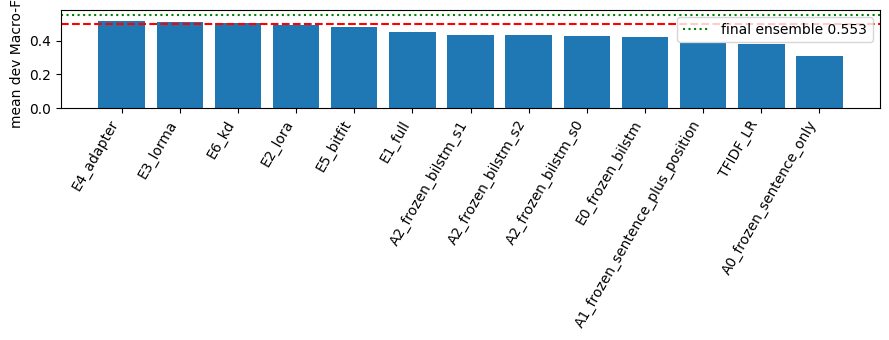

In [ ]:
# Per-class analysis of the final system on dev
for dom in ("CL", "IT"):
    yt = np.concatenate([d["y"] for d in DOCS[dom + "_dev"]])
    yp = np.concatenate([DECODER(FINAL_PROBS[dom + "_dev"][d["id"]], d["domain"]) for d in DOCS[dom + "_dev"]])
    present = sorted(set(yt) | set(yp))
    print(f"\n===== {dom} dev ====="); print(classification_report(yt, yp, labels=present, target_names=[LABELS[i] for i in present], zero_division=0))
    cm = confusion_matrix(yt, yp, labels=list(range(K))); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
    print("most frequent confusions (gold -> predicted):", [(LABELS[a], LABELS[b], int(cm[a, b])) for a, b in top])

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.5)); names = SUMMARY["experiment"].tolist(); vals = SUMMARY["mean_F1"].tolist()
ax.bar(names, vals); ax.axhline(0.5, ls="--", c="r"); ax.axhline(FINAL["mean"], ls=":", c="g", label=f"final ensemble {FINAL['mean']:.3f}")
ax.set_ylabel("mean dev Macro-F1"); plt.xticks(rotation=60, ha="right"); ax.legend(); plt.tight_layout(); plt.show()

## 12. Write the predictions and validate the format

In [ ]:
def predict_split_labels(split):
    pm = ens_probs(FINAL_MEMBERS)[split]; out = {}
    for d in DOCS[split]:
        labs = [id_to_label[int(i)] for i in DECODER(pm[d['id']], d['domain'])]
        assert len(labs) == d['n'] == len(d['sents']), d['id']
        assert all(l in label_to_id for l in labs)
        out[d['id']] = labs
    return out

sub = {}
for dom in ('CL', 'IT'):
    p = predict_split_labels(dom + '_test'); sub[dom] = p
    json.dump(p, open(os.path.join(OUTPUT_DIR, f'prediction_{dom}.json'), 'w'), ensure_ascii=False, indent=1)
overlap = set(sub['CL']) & set(sub['IT']); assert not overlap, f'CL/IT test ids overlap: {list(overlap)[:3]}'
combined = {**sub['CL'], **sub['IT']}
pj = os.path.join(OUTPUT_DIR, 'prediction.json'); json.dump(combined, open(pj, 'w'), ensure_ascii=False, indent=1)
zp = os.path.join(OUTPUT_DIR, 'submission.zip')
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z: z.write(pj, arcname='prediction.json')
print('test docs:', len(combined), '| sentences:', sum(len(v) for v in combined.values()), '->', zp)
print('predicted label distribution:', Counter(l for v in combined.values() for l in v).most_common())

test docs: 10 | sentences: 2197 -> /content/drive/MyDrive/CS781/Capstone-Project/Phase-3-v2/submission.zip
predicted label distribution: [('RatioOfTheDecision', 696), ('PrecedentReliedUpon', 415), ('Fact', 353), ('Statute', 185), ('ArgumentRespondent', 161), ('ArgumentPetitioner', 145), ('RulingByLowerCourt', 125), ('RulingByPresentCourt', 47), ('PrecedentNotReliedUpon', 31), ('None', 27), ('Issue', 12)]


In [ ]:
def predict_split_labels(split):
    pm = ens_probs(FINAL_MEMBERS)[split]; out = {}
    for d in DOCS[split]:
        labs = [id_to_label[int(i)] for i in DECODER(pm[d["id"]], d["domain"])]
        assert len(labs) == d["n"] == len(d["sents"]), d["id"]
        assert all(l in label_to_id for l in labs)
        out[d["id"]] = labs
    return out

sub = {}
for dom in ("CL", "IT"):
    p = predict_split_labels(dom + "_test"); sub[dom] = p
    json.dump(p, open(os.path.join(OUTPUT_DIR, f"prediction_{dom}.json"), "w"), ensure_ascii=False, indent=1)
overlap = set(sub["CL"]) & set(sub["IT"]); assert not overlap, f"CL/IT test ids overlap: {list(overlap)[:3]}"
combined = {**sub["CL"], **sub["IT"]}
pj = os.path.join(OUTPUT_DIR, "prediction.json"); json.dump(combined, open(pj, "w"), ensure_ascii=False, indent=1)
zp = os.path.join(OUTPUT_DIR, "submission.zip")
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(pj, arcname="prediction.json")     # file at the zip root
print("test docs:", len(combined), "| sentences:", sum(len(v) for v in combined.values()), "->", zp)
print("predicted label distribution:", Counter(l for v in combined.values() for l in v).most_common())

test docs: 10 | sentences: 2197 -> /content/drive/MyDrive/CS781/Capstone-Project/Phase-3-v2/submission.zip
predicted label distribution: [('RatioOfTheDecision', 696), ('PrecedentReliedUpon', 415), ('Fact', 353), ('Statute', 185), ('ArgumentRespondent', 161), ('ArgumentPetitioner', 145), ('RulingByLowerCourt', 125), ('RulingByPresentCourt', 47), ('PrecedentNotReliedUpon', 31), ('None', 27), ('Issue', 12)]


In [ ]:
import shutil

# Define source paths
source_prediction = os.path.join(OUTPUT_DIR, 'prediction.json')
source_submission = os.path.join(OUTPUT_DIR, 'submission.zip')

# Define the target directories
target_prediction_dir = os.path.join(OUTPUT_DIR, 'predictions')
target_submission_dir = os.path.join(OUTPUT_DIR, 'submissions')

# Create target directories if they don't exist
os.makedirs(target_prediction_dir, exist_ok=True)
os.makedirs(target_submission_dir, exist_ok=True)

# Move/copy files to respective folders
shutil.copy(source_prediction, os.path.join(target_prediction_dir, 'prediction.json'))
shutil.copy(source_submission, os.path.join(target_submission_dir, 'submission.zip'))

print(f"prediction.json copied to: {target_prediction_dir}")
print(f"submission.zip copied to: {target_submission_dir}")

prediction.json copied to: /content/drive/MyDrive/CS781/Capstone-Project/Phase-3-v2/predictions
submission.zip copied to: /content/drive/MyDrive/CS781/Capstone-Project/Phase-3-v2/submissions


## 13. Reading the results honestly
- **What should drive the gain:** document context (BiLSTM) + position features + class-balanced loss, then ensembling. Compare `A0` (sentence only) → `A1` (+position) → `E0` (+BiLSTM context) in the table: that is your *context ablation*.
- **0.5 is not guaranteed.** I could not run this on your data or GPU. With only 40 training documents per domain and a 5-document dev set, F1 estimates have roughly ±0.05 noise, and the 13-label strict score will be lower than the sklearn-default one whenever a class is absent from the dev set (Dissent, PrecedentOverruled, PrecedentNotReliedUpon). Look at the per-class report to see which rare classes cap the macro average.
- **If you are still below target**, in order of expected payoff: (1) raise `EPOCHS`/lower `PATIENCE` strictness for E2–E5 only if dev is still improving; (2) increase `WINDOW` to 64 (more context per BiLSTM window; needs more GPU memory); (3) refit the best configs on train+dev for the final test run; (4) add a CRF layer or a transformer-over-sentences document head; (5) add neighbouring-sentence text as a prefix to the GQLA input.
- **LoRMA:** see the note in section 5; verify the formulation against the paper.
- **Security:** the old notebook contained a hard-coded Hugging Face token. Revoke it at huggingface.co/settings/tokens and create a new one stored as a Colab secret.